In [1]:
import numpy             as np
import proplot           as pplt
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import pickle
import os

# ___Process transient simulations___

## ___1. Load simulations___

Specifications and indices

In [2]:
# Paths
# =====

main_path   = os.path.dirname(os.getcwd())
output_path = main_path + '/hpc/transient_standard/'
input_path  = main_path + '/input/'

# Specs
# =====

lat       = np.arange(-87.5, 87.5+5, 5)  # latitude centre
latb      = np.arange(-90., 90.+5, 5)    # latitude bounds
ilat      = np.arange(40.5, 89.5+1, 1)   # latitude centre (ice grid)
ilatb     = np.arange(40., 90.+1, 1)     # latitude bounds (ice grid)
res       = 5.0                          # resolution 
version   = 'moist'                      # model version 
tsk       = 0                            # time skip (model spin-up time)

# Indexes
# =======

# all, land,   ocean
idx,   idxl,   idxo   = {}, {}, {} # latitude centre
idx_b, idxl_b, idxo_b = {}, {}, {} # latitude bounds

for index in [idx, idxl, idxo, idx_b, idxl_b, idxo_b]:

    if  index == idx or index == idxl or index == idxo:
        latitude = lat.copy()
        
    elif index == idx_b or index == idxl_b or index == idxo_b:
        latitude = latb.copy()

    # index for specific latitudes
    for i in latitude:
        index[str(i)] = np.where(latitude == i)[0][0]

     # index for latitude zones
    index['60N_90N'] = np.where( (latitude>60. ) & (latitude < 90.) )[0]
    index['30N_60N'] = np.where( (latitude>30. ) & (latitude < 60.) )[0]
    index['0EQ_30N'] = np.where( (latitude> 0. ) & (latitude < 30.) )[0]
    index['0EQ_30S'] = np.where( (latitude< 0. ) & (latitude >-30.) )[0]
    index['30S_60S'] = np.where( (latitude<-30.) & (latitude >-60.) )[0]
    index['60S_90S'] = np.where( (latitude<-60.) & (latitude >-90.) )[0]

    # index for hemispheres
    index['NH']  = np.where( (latitude > 0. ) & (latitude < 90.) )[0]
    index['SH']  = np.where( (latitude < 0. ) & (latitude >-90.) )[0]

    # index for tropics
    index['TRP'] = np.where( (latitude < 30.) & (latitude >-30.) )[0]

    # index for entire globe
    index['GLB'] = np.where( (latitude < 90.) & (latitude >-90.) )[0]

# remove nan values for land and ocean
# ====================================

# grid centres

for key in idxl.keys():  # land
    for element in [5,6,34,35]:
        index     = np.argwhere(idxl[key] == element).flatten()
        idxl[key] = np.delete(idxl[key], index)  
        
for key in idxo.keys(): # ocean
    for element in [0,1,2]: 
        index     = np.argwhere(idxo[key] == element).flatten()
        idxo[key] = np.delete(idxo[key], index)

# grid boundaries

for key in idxl_b.keys():  # land
    for element in [5,6,34,35]:
        index     = np.argwhere(idxl_b[key] == element).flatten()
        idxl_b[key] = np.delete(idxl_b[key], index)  

for key in idxo_b.keys(): # ocean
    for element in [0,1,2]: 
        index     = np.argwhere(idxo_b[key] == element).flatten()
        idxo_b[key] = np.delete(idxo_b[key], index)


# function to calculate summer and winter averages
# ================================================

def calculate_seasons(var, method='mean'):

    '''
    For variable (var) with full seasonal cycle [e.g. year, latitude, day]:

    this function calculates the summer and winter averages ...
    '''

    # shape
    s = var.shape

    # initialize seasonal averages
    djf = np.zeros((s[0],s[1])) # summer
    jja = np.zeros((s[0],s[1])) # winter
    amj = np.zeros((s[0],s[1])) # winter

    # for year
    for i1 in np.arange(0, s[0]):    

        # for latitude
        for i2 in np.arange(0, s[1]): 

            # find seasonal cycle
            var_snl = var[i1,i2,:].copy()  # variable

            if method == 'mean':
                # summer average
                jja[i1,i2] = var_snl[151:242+1].mean()
                # summer average
                amj[i1,i2] = var_snl[90:181+1].mean()
                # winter average
                djf[i1,i2] = np.append(var_snl[0:58+1], var_snl[334:]).mean()

            if method == 'sum':
                # summer average
                jja[i1,i2] = var_snl[151:242+1].sum()
                amj[i1,i2] = var_snl[90:181+1].sum()
                # winter average
                djf[i1,i2] = np.append(var_snl[0:58+1], var_snl[334:]).sum()

    return jja, amj, djf



Function to load data.

In [3]:
def load_simulation(sim_name, sim_data, type, tsk):

    # =======
    # version
    # =======
    
    if sim_name == 'dry':
        version = 'dry'
    else:
        version = 'moist'

    # =========
    # load data
    # =========

    with open( f'{output_path}input_{type}_{sim_name}/output_{type}_{sim_name}_{version}_res{res}.pkl', 'rb') as file:
            data = pickle.load(file)
            
    # ===================
    # constants and input
    # ===================

    # constants
    sim_data['Var'] = data['Var']   
    Var             = sim_data['Var']

    # input
    sim_data['Input'] = data['Input']

    # ========
    # settings
    # ========

    # input
    sim_data['Settings'] = data['Settings']

    # ==========
    # insolation
    # ==========

    I = data['I'][tsk:,:,:] # raw data [year, latitude, day]
    sim_data['I_rw'] = I
    sim_data['I_yr'] = I.mean(axis=2)      # annual mean [year, latitude]

    # summer solstice insolation [year]
    sim_data['SSI']      = (I[:,:,171]  + I[:,:,171])  * 0.5 
    sim_data['SSI_65N']  = (I[:,30,171] + I[:,31,171]) * 0.5  
    sim_data['SSI_65S']  = (I[:,4,354]  + I[:,4,354])  * 0.5

    # integreated summer insolation [year]
    sim_data['ISI']      = (I.sum(axis=2, where=(I>275)) * 86400 ) / 1e9   # converted to GJ m2
    sim_data['ISIdays']  = (I>275).sum(axis=2)
    sim_data['ISIavg']   = I.mean(axis=2, where=(I>275))  
    sim_data['ISI_65N']  = (sim_data['ISI'][:,30] + sim_data['ISI'][:,31]) * 0.5  
    sim_data['ISI_65S']  = (sim_data['ISI'][:,4]  + sim_data['ISI'][:,5])  * 0.5
    sim_data['ISI_65Ndays']  = (sim_data['ISIdays'][:,30] + sim_data['ISIdays'][:,31]) * 0.5
    sim_data['ISI_65Navg']  = (sim_data['ISIavg'][:,30] + sim_data['ISIavg'][:,31]) * 0.5

    # average caloric summer half year [year]
    sim_data['CSH']      = (np.sort(I, axis=2)[:,:,183:].sum(axis=2) * 86400 ) / 1e9  # converted to GJ m2
    sim_data['CSH_65N']  = (sim_data['CSH'][:,30] + sim_data['CSH'][:,31]) * 0.5 
    sim_data['CSH_65S']  = (sim_data['CSH'][:,4]  + sim_data['CSH'][:,5])  * 0.5

    # zonal averages
    for nm, vl in idx.items():
        if vl.size > 1:
            sim_data[f"SSI_{nm}"] = np.average(sim_data['SSI'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl])
            sim_data[f"CSH_{nm}"] = np.average(sim_data['CSH'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl])
            sim_data[f"ISI_{nm}"] = np.average(sim_data['ISI'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl])
        else:
            sim_data[f"SSI_{nm}"] = sim_data['SSI'][:,vl]   
            sim_data[f"CSH_{nm}"] = sim_data['CSH'][:,vl]   
            sim_data[f"ISI_{nm}"] = sim_data['ISI'][:,vl]  

    # ==================
    # orbital parameters
    # ==================

    # eccentricity    
    sim_data['ecc'] = data['ecc'][tsk:]

    # precession
    sim_data['pre'] = data['pre'][tsk:]

    # climatic precession
    sim_data['esinw'] = sim_data['ecc']*np.sin(sim_data['pre'])

    # obliquity
    sim_data['obl'] = data['obl'][tsk:]

    # =================
    # CO2 concentration
    # =================
    
    sim_data['CO2'] = data['CO2'][tsk:] / ((44.01/28.97) * 1e-6)

    # =======================
    # surface air temperature
    # =======================
    
    sim_data['Ta_rw'] = data['Ta'][tsk:,:,:]-273.15     # raw data [year, latitude, day]
    sim_data['Ta']    = sim_data['Ta_rw'].mean(axis=2)  # annual mean [year, latitude]

    # seasons
    sim_data['Ta_JJA'], sim_data['Ta_AMJ'], sim_data['Ta_DJF'] = calculate_seasons(sim_data['Ta_rw'], method='mean')

    # zonal averages
    for nm, vl in idx.items():
        if vl.size > 1:
            sim_data[f"Ta_{nm}"] = np.average(sim_data['Ta'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl]) 
            sim_data[f"Ta_JJA_{nm}"] = np.average(sim_data['Ta_JJA'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl]) 
            sim_data[f"Ta_AMJ_{nm}"] = np.average(sim_data['Ta_AMJ'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl]) 
            sim_data[f"Ta_DJF_{nm}"] = np.average(sim_data['Ta_DJF'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl]) 
            
        else:
            sim_data[f"Ta_{nm}"] = sim_data['Ta'][:,vl]
            sim_data[f"Ta_JJA_{nm}"] = sim_data['Ta_JJA'][:,vl]
            sim_data[f"Ta_AMJ_{nm}"] = sim_data['Ta_AMJ'][:,vl]
            sim_data[f"Ta_DJF_{nm}"] = sim_data['Ta_DJF'][:,vl]

    # ====================
    # surface air humidity
    # ====================

    sim_data['Q'] = data['Q'][tsk:, :]

    # zonal averages
    for nm, vl in idx.items():
        if vl.size > 1:
            sim_data[f"Q_{nm}"] = np.average(sim_data['Q'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl]) 
        else:
            sim_data[f"Q_{nm}"] = sim_data['Q'][:,vl]

    # ====================================
    # Equator-to-pole temperature gradient
    # ====================================

    # NH
    eqn = np.where( (lat>0.)  & (lat < 30.))[0]
    pln = np.where( (lat>60.) & (lat < 90.))[0]
    sim_data['dT_NH'] = (sim_data['Ta'][:,eqn].mean(axis=1) - sim_data['Ta'][:,pln].mean(axis=1))/80 # [year] 

    # SH
    eqs = np.where( (lat>-30.)  & (lat < 0.))[0]
    pls = np.where( (lat>-90.) & (lat < -60.))[0]
    sim_data['dT_SH'] = (sim_data['Ta'][:,eqs].mean(axis=1) - sim_data['Ta'][:,pls].mean(axis=1))/80 # [year] 

    # ============================
    # Equator-to-pole MSE gradient
    # ============================
  
    ms=sim_data['Var']["atm_sphc"]*sim_data['Ta'] # dry static energy
    ml=sim_data['Var']["Lv"]*sim_data['Q']        # latent energy
    mse=ms+ml                                     # moist static energy

    sim_data['dMSE_NH'] = (mse[:,eqn].mean(axis=1) - mse[:,pln].mean(axis=1))/80 # [year] 
    sim_data['dMSE_SH'] = (mse[:,eqs].mean(axis=1) - mse[:,pls].mean(axis=1))/80 # [year] 

    sim_data['dQ_NH'] = (ml[:,eqn].mean(axis=1) - ml[:,pln].mean(axis=1))/80 # [year] 
    sim_data['dQ_SH'] = (ml[:,eqs].mean(axis=1) - ml[:,pls].mean(axis=1))/80 # [year] 

    # ============================
    # atmospheric latent transport
    # ============================

    sim_data['latent']      = data['atm_latent'][tsk:, :]*1e-15 # annual mean [year, latitude]
    sim_data['latent_65N']  = sim_data['latent'][:,31] # [year]
    sim_data['latent_65S']  = sim_data['latent'][:,5]  # [year]

    # zonal averages
    for nm, vl in idx_b.items():
        if vl.size > 1:
            sim_data[f"latent_{nm}"] = np.average(sim_data['latent'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl]) 
        else:
            sim_data[f"latent_{nm}"] = sim_data['latent'][:,vl]   

    # =========================
    # atmospheric dry transport
    # =========================

    sim_data['dry']      = data['atm_dry'][tsk:, :]*1e-15                  # annual mean [year, latitude]
    sim_data['dry_65N']  = sim_data['dry'][:,31] # [year]
    sim_data['dry_65S']  = sim_data['dry'][:,5]  # [year]

    # zonal averages
    for nm, vl in idx_b.items():
        if vl.size > 1:
            sim_data[f"dry_{nm}"] = np.average(sim_data['dry'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl]) 
        else:
            sim_data[f"dry_{nm}"] = sim_data['dry'][:,vl]

    # atmospheric heat transport
    # ==========================

    sim_data['AHT']     = sim_data['dry'] + sim_data['latent']
    sim_data['AHT_60N'] = sim_data['AHT'][:,31] # [year]
    sim_data['AHT_60S'] = sim_data['AHT'][:,5]  # [year]

    # zonal averages
    for nm, vl in idx_b.items():
        if vl.size > 1:
            sim_data[f"AHT_{nm}"] = np.average(sim_data['AHT'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl]) 
        else:
            sim_data[f"AHT_{nm}"] = sim_data['AHT'][:,vl]  

    # ocean heat transport
    # ====================

    OHT = data['ocean'][tsk:, :]*1e-15 # convert to petawatts
    sim_data['OHT'] = np.zeros((OHT.shape[0], latb.size))
    sim_data['OHT'][:,4:35]=OHT
    sim_data['OHT_60N']  = sim_data['OHT'][:,31] # [year]
    sim_data['OHT_60S']  = sim_data['OHT'][:,5]  # [year]

    # zonal averages
    for nm, vl in idxo_b.items():
        if vl.size > 1:
            sim_data[f"OHT_{nm}"] = np.average(sim_data['OHT'][:,vl], axis=1, weights=sim_data['Var']['oarea'][vl]) 
        else:
            sim_data[f"OHT_{nm}"] = sim_data['OHT'][:,vl] 

    # total heat transport
    # ====================

    sim_data['MHT'] = sim_data['OHT'] + sim_data['dry'] + sim_data['latent']
    sim_data['MHT_60N'] = sim_data['MHT'][:,31] # [year]
    sim_data['MHT_60S'] = sim_data['MHT'][:,5]  # [year]

    # zonal averages
    for nm, vl in idx_b.items():
        if vl.size > 1:
            sim_data[f"MHT_{nm}"] = np.average(sim_data['MHT'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl]) 
        else:
            sim_data[f"MHT_{nm}"] = sim_data['MHT'][:,vl]


    # surface heat fluxes at the ocean
    # ================================
            
    sim_data['shf_ocean_rw'] = data['shf_ocean'][tsk:, :, :] # annual mean [year, latitude, day]
    sim_data['rlus_ocean_rw'] = data['rlus_ocean'][tsk:, :, :] # annual mean [year, latitude, day]
    sim_data['lhf_evap_ocean_rw'] = data['lhf_evap_ocean'][tsk:, :, :] # annual mean [year, latitude, day]

    sim_data['surf_ocean_rw'] = sim_data['shf_ocean_rw'] + sim_data['rlus_ocean_rw'] + sim_data['lhf_evap_ocean_rw']

    # seasons
    sim_data['surf_ocean_JJA'], sim_data['surf_ocean_AMJ'], sim_data['surf_ocean_DJF'] = calculate_seasons(sim_data['surf_ocean_rw'], method='mean')

    # annual [year, latitude]
    sim_data['shf_ocean']      = sim_data['shf_ocean_rw'].mean(axis=2)
    sim_data['rlus_ocean']     = sim_data['rlus_ocean_rw'].mean(axis=2)
    sim_data['lhf_evap_ocean'] = sim_data['lhf_evap_ocean_rw'].mean(axis=2)
    sim_data['surf_ocean']     = sim_data['surf_ocean_rw'].mean(axis=2)
    
    # zonal averages
    for nm, vl in idxo.items():
        if vl.size > 1:
            sim_data[f"shf_ocean_{nm}"]      = np.average(sim_data['shf_ocean'][:,vl], axis=1, weights=sim_data['Var']['oarea'][vl])
            sim_data[f"rlus_ocean_{nm}"]     = np.average(sim_data['rlus_ocean'][:,vl], axis=1, weights=sim_data['Var']['oarea'][vl])
            sim_data[f"lhf_evap_ocean_{nm}"] = np.average(sim_data['lhf_evap_ocean'][:,vl], axis=1, weights=sim_data['Var']['oarea'][vl])
            sim_data[f"surf_ocean_{nm}"]     = np.average(sim_data['surf_ocean'][:,vl], axis=1, weights=sim_data['Var']['oarea'][vl])
            sim_data[f"surf_ocean_DJF_{nm}"] = np.average(sim_data['surf_ocean_DJF'][:,vl], axis=1, weights=sim_data['Var']['oarea'][vl])
            sim_data[f"surf_ocean_JJA_{nm}"] = np.average(sim_data['surf_ocean_JJA'][:,vl], axis=1, weights=sim_data['Var']['oarea'][vl])
            sim_data[f"surf_ocean_AMJ_{nm}"] = np.average(sim_data['surf_ocean_AMJ'][:,vl], axis=1, weights=sim_data['Var']['oarea'][vl])
                    

        else:
            sim_data[f"shf_ocean_{nm}"]      = sim_data['shf_ocean'][:,vl]
            sim_data[f"rlus_ocean_{nm}"]     = sim_data['rlus_ocean'][:,vl]
            sim_data[f"lhf_evap_ocean_{nm}"] = sim_data['lhf_evap_ocean'][:,vl]    
            sim_data[f"surf_ocean_{nm}"]     = sim_data['surf_ocean'][:,vl] 
            sim_data[f"surf_ocean_DJF_{nm}"] = sim_data['surf_ocean_DJF'][:,vl] 
            sim_data[f"surf_ocean_JJA_{nm}"] = sim_data['surf_ocean_JJA'][:,vl] 
            sim_data[f"surf_ocean_AMJ_{nm}"] = sim_data['surf_ocean_AMJ'][:,vl] 


    # surface heat fluxes
    # ===================

    sim_data['shf'] =data['shf'][tsk:, :] # annual mean [year, latitude]
    sim_data['rlus'] = data['rlus'][tsk:, :] # annual mean [year, latitude]
    sim_data['lhf_evap'] = data['lhf_evap'][tsk:, :] # annual mean [year, latitude]

    sim_data['surf'] = sim_data['shf'] + sim_data['rlus'] + sim_data['lhf_evap']

    # zonal averages
    for nm, vl in idx.items():
        if vl.size > 1:
            sim_data[f"shf_{nm}"] = np.average(sim_data['shf'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl])
            sim_data[f"rlus_{nm}"] = np.average(sim_data['rlus'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl])
            sim_data[f"lhf_evap_{nm}"] = np.average(sim_data['lhf_evap'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl])
            sim_data[f"surf_{nm}"] = np.average(sim_data['surf'][:,vl], axis=1, weights=sim_data['Var']['sarea'][vl])
        else:
            sim_data[f"shf_{nm}"] = sim_data['shf'][:,vl]
            sim_data[f"rlus_{nm}"] = sim_data['rlus'][:,vl]
            sim_data[f"lhf_evap_{nm}"] = sim_data['lhf_evap'][:,vl]     
            sim_data[f"surf_{nm}"] = sim_data['surf'][:,vl] 


    
    # land surface temperature
    # ========================

    if sim_name == 'lgm' or sim_name == 'preMPTgl' or sim_name == 'co2_trend':
        Tl = data['Tl'][tsk:, :, :] - 273.15 # converted to degrees celsius
        sim_data['Tl'] = Tl.mean(axis=2) # annual mean [year, latitude]

    else:
        Tl = data['Tl'][tsk:, :] - 273.15 # converted to degrees celsius
        sim_data['Tl'] = Tl # annual mean [year, latitude]

    # zonal averages
    for nm, vl in idxl.items():
        if vl.size > 1:
            sim_data[f"Tl_{nm}"] = np.average(sim_data['Tl'][:,vl], axis=1, weights=sim_data['Var']['larea'][vl]) 
        else:
            sim_data[f"Tl_{nm}"] = sim_data['Tl'][:,vl]


    # surface ocean temperature
    # =========================

    if sim_name == 'lgm' or sim_name == 'preMPTgl' or sim_name == 'co2_trend':
        Tos = data['Tos'][tsk:, :, :] - 273.15 # converted to degrees celsius
        sim_data['Tos_rw'] = Tos - 273.15 # converted to degrees celsius
        sim_data['Tos'] = Tos.mean(axis=2)     # annual mean [year, latitude]

    else:
        Tos = data['Tos'][tsk:, :] - 273.15 # converted to degrees celsius
        sim_data['Tos'] = Tos               # annual mean [year, latitude]

    # zonal averages
    for nm, vl in idxo.items():
        if vl.size > 1:
            sim_data[f"Tos_{nm}"] = np.average(sim_data['Tos'][:,vl], axis=1, weights=sim_data['Var']['oarea'][vl]) 
        else:
            sim_data[f"Tos_{nm}"] = sim_data['Tos'][:,vl]

    # land albedo
    # ===========
    if sim_name == 'lgm' or sim_name == 'preMPTgl' or sim_name == 'co2_trend':
         sim_data['land_albedo'] = data['land_albedo'][tsk:, :, :].mean(axis=2) # annual mean [year, latitude]

    else:
        sim_data['land_albedo'] = data['land_albedo'][tsk:, :] # annual mean [year, latitude]


    # ocean albedo
    # ============

    if sim_name == 'lgm' or sim_name == 'preMPTgl' or sim_name == 'co2_trend':
        sim_data['ocean_albedo'] = data['ocean_albedo'][tsk:, :, :].mean(axis=2)  # annual mean [year, latitude]
    else:
        sim_data['ocean_albedo'] = data['ocean_albedo'][tsk:, :]  # annual mean [year, latitude]


    # sea-ice fraction
    # ================

    si_fraction = data['si_fraction'][tsk:, :, :] 

    # seasonal [year, latitude, day]
    sim_data['si_fraction_rw']  = si_fraction  # fractional

    sim_data['si_fraction_prn_rw']  = si_fraction.copy()
    ii = np.where(si_fraction<1.)
    sim_data['si_fraction_prn_rw'][ii] = 0.

    sim_data['si_area_rw']  = si_fraction.copy() # areal
    sim_data['si_area_prn_rw']  = si_fraction.copy()
    for i1 in np.arange(0, si_fraction.shape[0]):
        for i3 in np.arange(0, si_fraction.shape[2]):
            sim_data['si_area_rw'][i1,:,i3] = sim_data['si_fraction_rw'][i1,:,i3]*Var['oarea']
            sim_data['si_area_prn_rw'][i1,:,i3] = sim_data['si_fraction_prn_rw'][i1,:,i3]*Var['oarea']

    # seasons
    sim_data['si_area_JJA'], sim_data['si_area_AMJ'], sim_data['si_area_DJF'] = calculate_seasons(sim_data['si_area_rw'], method='mean')
    sim_data['si_area_JJA']=sim_data['si_area_JJA']* 1e-12 
    sim_data['si_area_DJF']=sim_data['si_area_DJF']* 1e-12  

    # zonal averages
    for nm, vl in idxo.items():
        if vl.size > 1:
            sim_data[f"si_area_DJF_{nm}"] = np.sum(sim_data['si_area_DJF'][:,vl], axis=1)  
            sim_data[f"si_area_JJA_{nm}"] = np.sum(sim_data['si_area_JJA'][:,vl], axis=1) 
    
        else:
            sim_data[f"si_area_DJF_{nm}"] = sim_data['si_area_DJF'][:,vl]
            sim_data[f"si_area_JJA_{nm}"] = sim_data['si_area_JJA'][:,vl]


    # annual [year, latitude]
    # ======

    sim_data['si_fraction'] = si_fraction.mean(axis=2)
    sim_data['si_fraction_prn'] = sim_data['si_fraction_prn_rw'].mean(axis=2)
    sim_data['si_area']     = si_fraction.mean(axis=2) * Var['oarea'] * 1e-12    # annual mean [year, latitude]
    sim_data['si_area_prn']     = sim_data['si_fraction_prn_rw'].mean(axis=2) * Var['oarea'] * 1e-12

    
    # zonal averages
    for nm, vl in idxo.items():
        if vl.size > 1:
            sim_data[f"si_area_{nm}"] = np.sum(sim_data['si_area'][:,vl], axis=1)
            sim_data[f"si_area_prn_{nm}"] = np.sum(sim_data['si_area_prn'][:,vl], axis=1) 
        else:
            sim_data[f"si_area_{nm}"] = sim_data['si_area'][:,vl]
            sim_data[f"si_area_prn_{nm}"] = sim_data['si_area_prn'][:,vl]


    # snow-cover fraction
    # ===================

    sc_fraction = data['sc_fraction'][tsk:, :, :] 
    sim_data['sc_fraction_rw']  = sc_fraction                                       # raw data [year, latitude, day]
    sim_data['sc_fraction']     = sc_fraction.mean(axis=2)                          # annual mean [year, latitude]
    sim_data['sc_area']         = sc_fraction.mean(axis=2) * Var['larea'] * 1e-12   # annual mean [year, latitude]

    # zonal averages
    for nm, vl in idxl.items():
        if vl.size > 1:
            sim_data[f"sc_area_{nm}"] = np.sum(sim_data['sc_area'][:,vl], axis=1) 
        else:
            sim_data[f"sc_area_{nm}"] = sim_data['sc_area'][:,vl]

    # precipitation
    # =============

    if sim_name == 'lgm' or sim_name == 'preMPTgl' or sim_name == 'co2_trend':
        precip = (data['precip'][tsk:, :, :] / sim_data['Var']['water_rho']) * sim_data['Var']['secs_in_day'] * 365 # converted to mm/yr
        sim_data['precip'] = precip.mean(axis=2) # annual mean [year, latitude]

    else: 
        precip = (data['precip'][tsk:, :] / sim_data['Var']['water_rho']) * sim_data['Var']['secs_in_day'] * 365 # converted to mm/yr
        sim_data['precip'] = precip # annual mean [year, latitude]

    # zonal averages
    for nm, vl in idxl.items():
        if vl.size > 1:
            sim_data[f"precip_{nm}"] = np.sum(sim_data['precip'][:,vl], axis=1) 
        else:
            sim_data[f"precip_{nm}"] = sim_data['precip'][:,vl]

    # snowfall
    # ========

    if sim_name == 'lgm' or sim_name == 'preMPTgl' or sim_name == 'co2_trend':

        snowfall = (data['snowfall'][tsk:, :, :] / sim_data['Var']['water_rho']) * sim_data['Var']['secs_in_day'] * 365 # converted to mm/yr
        sim_data['snowfall']  = snowfall.mean(axis=2) # annual mean [year, latitude]

    else:

        snowfall = (data['snowfall'][tsk:, :] / sim_data['Var']['water_rho']) * sim_data['Var']['secs_in_day'] * 365 # converted to mm/yr
        sim_data['snowfall']  = snowfall # annual mean [year, latitude]

    # zonal averages
    for nm, vl in idxl.items():
        if vl.size > 1:
            sim_data[f"snowfall_{nm}"] = np.sum(sim_data['snowfall'][:,vl], axis=1) 
        else:
            sim_data[f"snowfall_{nm}"] = sim_data['snowfall'][:,vl]

    return sim_data

In [4]:
# --- standard transient experiments ---

transient_experiment={ 

    'standard'  : {},   # standard
    'lgm'  :      {},   # LGM
    #'preMPTgl'  :      {},   # LGM
    #'co2_trend'  :      {},   # LGM
    'obliquity' : {},   # only obliquity (fixed precession)
    'precession': {},   # only precession (fixed obliquity)
    'fxoa'      : {},   # fixed ocean albedo
    'fxla'      : {},   # fixed land albedo
    'fxoa_fxla' : {},
  }
    

for sim_name, sim_data in transient_experiment.items(): 

    sim_data = load_simulation(sim_name, sim_data, type='transient', tsk=50)

Var = transient_experiment['standard']['Var']

## ___2. Spectral Analysis___

Spectral analysis of time-series using the Pyleoclim python package for analyzing paleoclimate data.

In [5]:
import pyleoclim as pyleo

# time axis
# =========

time = np.arange(2400, 1200-1, -1)

# list of variables for spectral analysis
# =======================================

spectral_list = [ # orbital
                  'pre', 'ecc', 'esinw', 'obl',

                  # insolation
                  'SSI_65N', 'SSI_65S', 'ISI_65N', 'ISI_65Ndays','ISI_65Navg', 'ISI_65S', 'CSH_65N', 'CSH_65S',

                  # equator-to-pole gradient
                  'dT_NH', 'dT_SH', 'dMSE_NH', 'dMSE_SH', 'dQ_NH', 'dQ_SH',

                  # sea ice and snow cover
                  'si_area_60N_90N', 'si_area_60S_90S', 'sc_area_60N_90N', 'sc_area_60S_90S',  

                  # co2
                  'CO2',

                  # atmospheric heat transport
                 'latent_65N', 'dry_65N', 'ocean_60N', 'ocean_60S', 'MHT_60N', 'MHT_60S', 'AHT_60N', 'AHT_60S',   

                ]

# append global and regional means
# ================================

for variable in ['Ta', 'Ta_DJF', 'Ta_AMJ', 'Ta_JJA', 'SSI', 'CSH', 'ISI', 'precip', 'snowfall', 'shf', 'lhf_evap', 'rlus', 'rtnet', 'Q', 'surf']:
    for index in idx.keys():
        spectral_list.append(f"{variable}_{index}")

for variable in ['latent', 'dry', 'AHT', 'OHT', 'MHT']:
    for index in idx_b.keys():
        spectral_list.append(f"{variable}_{index}")

for variable in ['Tl', 'melt', 'sc_area']:
    for index in idxl.keys():
        spectral_list.append(f"{variable}_{index}")

for variable in ['Tos', 'si_area', 'si_area_DJF', 'si_area_AMJ', 'si_area_JJA', 'shf_ocean', 'lhf_evap_ocean', 'rlus_ocean', 'surf_ocean', 'surf_ocean_AMJ', 'surf_ocean_DJF','surf_ocean_JJA']:
    for index in idxo.keys():
        spectral_list.append(f"{variable}_{index}")

# ===========================================
# Define dictionary for transient experiments
# ===========================================

series = {}
for key in transient_experiment.keys():
    series[key] = {}
    
for name, dic in zip(series.keys(), series.values()): # for each experiment

    for variable in spectral_list: # for each variable

        try:
            dic[variable]=pyleo.Series(time =  time, value = transient_experiment[name][variable], time_name = 'Kyr BP',  sort_ts='descending', verbose=False) # load into pyleoseries

        except:
            pass

In [6]:
# perform spectral analysis for transient simulations
# ===================================================

spectral = {}
for key in transient_experiment.keys():
    spectral[key] = {}

for dic, spec_dic in zip(series.values(), spectral.values()): # for each dictionary

    for variable in spectral_list: # for each variable

        try:
            spec_dic[variable]=dic[variable].standardize().interp().spectral(method='mtm', settings={'NW':4})
            
        except:
            pass

# ___Introduction Figure___

In [7]:
# Prob Stack...
prob_stack_time  = np.loadtxt('Prob_stack.txt', usecols=0)
prob_stack_value = np.loadtxt('Prob_stack.txt', usecols=1)
prob_stack=pyleo.Series(time =  prob_stack_time[900:1411], value = prob_stack_value[900:1411], time_name = 'Kyr BP',  sort_ts='descending')
prob_stack_psd=prob_stack.standardize().interp().spectral(method='mtm', settings={'NW':4})

Time axis values sorted in descending order


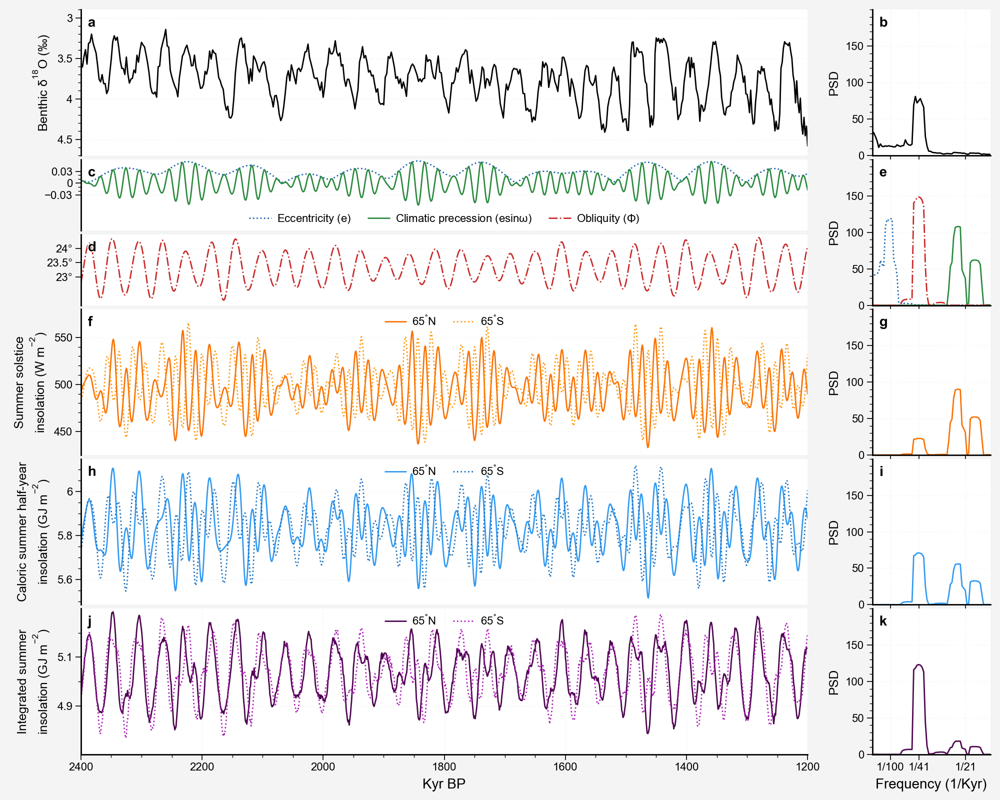

In [8]:
# Create figure
# =============

shape = [[1,1,1,1,1,1,1,1,1,1,1,1,0,2,2,],
         [1,1,1,1,1,1,1,1,1,1,1,1,0,2,2,],
         [3,3,3,3,3,3,3,3,3,3,3,3,0,5,5,],
         [4,4,4,4,4,4,4,4,4,4,4,4,0,5,5,],
         [6,6,6,6,6,6,6,6,6,6,6,6,0,7,7,],
         [6,6,6,6,6,6,6,6,6,6,6,6,0,7,7,],
         [8,8,8,8,8,8,8,8,8,8,8,8,0,9,9,],
         [8,8,8,8,8,8,8,8,8,8,8,8,0,9,9,],
         [10,10,10,10,10,10,10,10,10,10,10,10,0,11,11],
         [10,10,10,10,10,10,10,10,10,10,10,10,0,11,11],]

fig, axs = pplt.subplots(shape, sharey = False, sharex=False, figsize = (10, 8), space=0.2, abc=True, abcbbox=False, abcloc='ul', abcsize=10)

# Plot benthic d18O stack from Ahn et al., 2017
# =============================================

stack_line = axs[0].plot(prob_stack.time, prob_stack.value, color = 'black', ls = '-', lw = 1) 
axs[1].plot(prob_stack_psd.frequency, prob_stack_psd.amplitude, color = 'black', ls = '-', lw = 1) 
axs[0].invert_yaxis()
axs[0].format(ylim=(4.7, 2.9))

# Plot orbital parameters
# =======================

# eccentricity
ecc_line = axs[2].plot(series['standard']['ecc'].time, series['standard']['ecc'].value, color = 'blue9', ls = ':', lw = 1)
axs[4].plot(spectral['standard']['ecc'].frequency, spectral['standard']['ecc'].amplitude, color = 'blue9', ls = ':', lw = 1)

# climatic precession
pre_line = axs[2].plot(series['standard']['esinw'].time, series['standard']['esinw'].value, color = 'green9', lw = 1)
axs[2].format(ylim=(-0.12, 0.06), ylocator=[-0.03, 0., 0.03], yminorlocator=np.arange(-0.03, 0.03, 0.01))
axs[4].plot(spectral['standard']['esinw'].frequency, spectral['standard']['esinw'].amplitude, color = 'green9', lw = 1)

# obliquity
obl_line = axs[3].plot(series['standard']['obl'].time, np.rad2deg(series['standard']['obl'].value), color = 'red9', ls = '-.', lw = 1)
axs[3].format(ylim=(22, 24.5), ylocator=[23, 23.5, 24], yminorlocator=[], yformatter='deg')
axs[4].plot(spectral['standard']['obl'].frequency, spectral['standard']['obl'].amplitude, color = 'red9', ls = '-.', lw = 1)

# legend
legend = axs[2].legend(handles=[ecc_line, pre_line, obl_line], labels = [r'Eccentricity ($e$)', 'Climatic precession ($e$sin$\omega$)', r'Obliquity ($\Phi$)'], loc = 'lc', prop={'size': 8})

# Plot summer insolation metrics
# ==============================

# summer solstice insolation
I65N_JUN21_line = axs[5].plot(series['standard']['SSI_65N'].time, series['standard']['SSI_65N'].value, color = 'orange', ls = '-', lw = 1) 
I65S_DEC21_line = axs[5].plot(series['standard']['SSI_65S'].time, series['standard']['SSI_65S'].value, color = 'tangerine', ls = ':', lw = 1) 
axs[5].format(ylim=(425, 580), ylocator=[450, 500, 550], yminorlocator=np.arange(450, 550+10,10))
axs[5].legend(handles=[I65N_JUN21_line, I65S_DEC21_line], labels = [r'65$^{\circ}N$', r'65$^{\circ}S$'], loc = 'uc', prop={'size': 8})
axs[6].plot(spectral['standard']['SSI_65N'].frequency, spectral['standard']['SSI_65N'].amplitude, color = 'orange', ls = '-', lw = 1) 

# average caloric summer half-year insolation
I65N_CSH_line = axs[7].plot(series['standard']['CSH_65N'].time, series['standard']['CSH_65N'].value, color = 'blue5', ls = '-', lw = 1) 
I65S_CSH_line = axs[7].plot(series['standard']['CSH_65S'].time, series['standard']['CSH_65S'].value, color = 'blue8', ls = ':', lw = 1)
axs[7].legend(handles=[I65N_CSH_line, I65S_CSH_line], labels = [r'65$^{\circ}N$', r'65$^{\circ}S$'], loc = 'uc', prop={'size': 8})
axs[8].plot(spectral['standard']['CSH_65N'].frequency, spectral['standard']['CSH_65N'].amplitude, color = 'blue5', ls = '-', lw = 1) 

# integrated summer insolation
I65N_ISI_line = axs[9].plot(series['standard']['ISI_65N'].time, series['standard']['ISI_65N'].value, color = 'plum purple', ls = '-', lw = 1) 
I65S_ISI_line = axs[9].plot(series['standard']['ISI_65S'].time, series['standard']['ISI_65S'].value, color = 'barney', ls = ':', lw = 1)
axs[9].legend(handles=[I65N_ISI_line, I65S_ISI_line], labels = [r'65$^{\circ}N$', r'65$^{\circ}S$'], loc = 'uc', prop={'size': 8})
axs[9].format(ylim=(4.7, 5.3), ylocator = np.arange(4.9, 5.3, 0.2), yminorlocator = np.arange(4.9, 5.3, 0.1))
axs[10].plot(spectral['standard']['ISI_65N'].frequency, spectral['standard']['ISI_65N'].amplitude, color = 'plum purple', ls = '-', lw = 1) 


# Formatting
# ==========

for i in [0,2,3,5,7]:
    axs[i].spines[['bottom']].set_visible(False)
    axs[i].get_xaxis().set_visible(False)
    
for i in [1,4,6,8,10]:
    axs[i].format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xticklabels=[r'1/100','1/41','1/21'], xlim = (0.001, 0.06), xticklabelsize=10, ylabel='PSD')
    axs[i].format(ylim = (0, 200), ylocator = [0, 50, 100, 150])
    if i != 10:
        axs[i].xaxis.set_ticklabels([])
    
# titles
axs.format(titlesize=7)
axs[0].format(ylabel='Benthic $\delta^{18}$O (‰)')
axs[5].format(ylabel='Summer solstice\ninsolation (W m$^{-2}$)')
axs[7].format(ylabel='Caloric summer half-year\ninsolation (GJ m$^{-2}$)')
axs[9].format(ylabel='Integrated summer\ninsolation (GJ m$^{-2}$)')

axs[9].format(xlabel = 'Kyr BP')
axs[10].format(xlabel = 'Frequency (1/Kyr)')

axs.format(ylabelsize=9, xlabelsize=10, ticklabelsize=8, )

fig.save('paper2/f01_intro.png', dpi=300)

# ___Changes in ZEMBA for the standard transient simulation___

## _1a: Changes in in the NH polar regions_

Plots changes in temperature, sea ice, snow cover, precipitation, snowfall, latent and dry atmospheric heat transport.

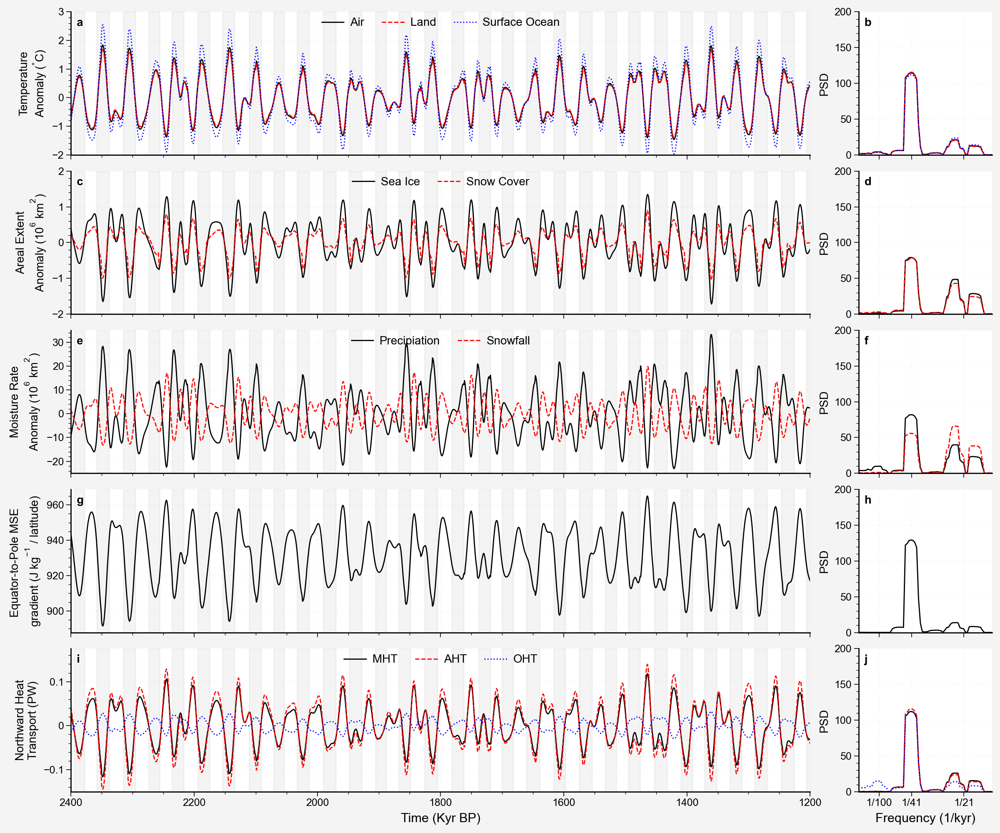

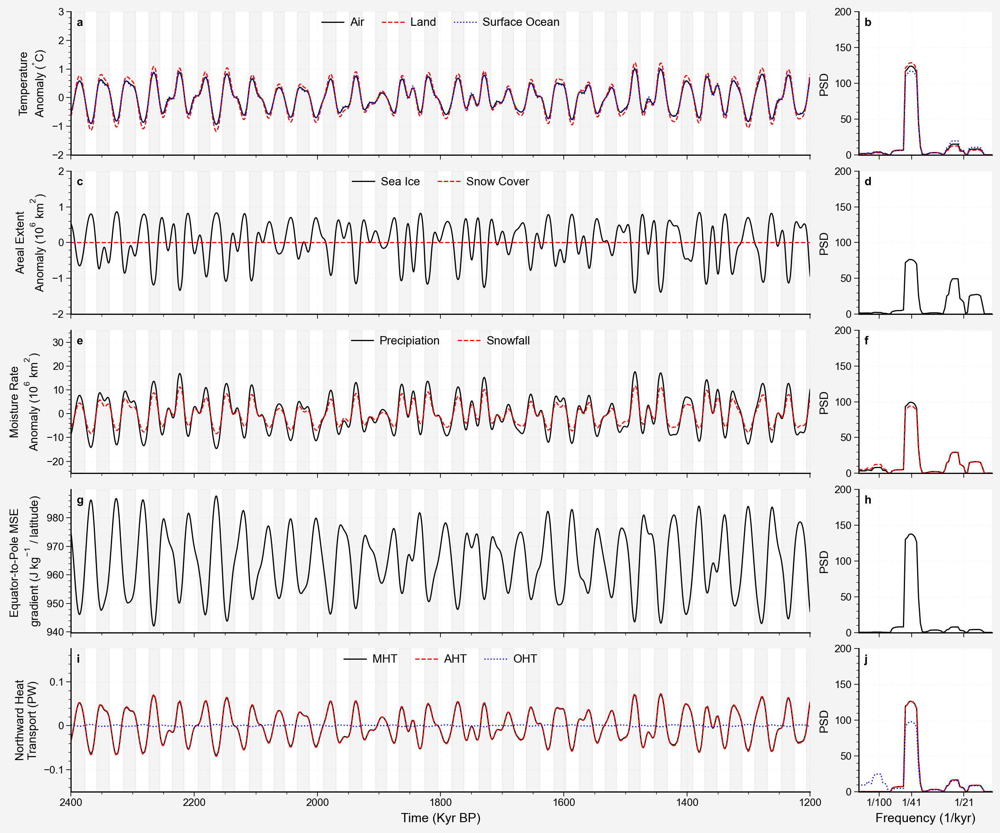

In [27]:
def plot_std_NH(t1,t2, region='NHP'):

    '''
    Plot standard transient simulation of ZEMBA in response to varying orbital parameters.
    '''

    if region == 'NHP':
        reg = '60N_90N'
        reg2='60.0'
        reg3= 'NH'

    if region == 'SHP':
        reg = '60S_90S'
        reg2= '-60.0'
        reg3= 'SH'

    exp=series['standard'].copy()
    exp_psd=spectral['standard'].copy()

    # Create figure
    # =============
    
    shape = [[1,1,1,1,1,1,1,1,1,1,1,1,1,2,2,2],
             [3,3,3,3,3,3,3,3,3,3,3,3,3,4,4,4],
             [5,5,5,5,5,5,5,5,5,5,5,5,5,6,6,6],
             [7,7,7,7,7,7,7,7,7,7,7,7,7,8,8,8],
             [9,9,9,9,9,9,9,9,9,9,9,9,9,10,10,10],]
    
    fig, axs = pplt.subplots(shape, figsize = (12,10), sharey = False, sharex=False, abc=True, abcbbox=False, abcloc='ul', abcsize=10, wspace=3., hspace=1)
    
    # Plot temperature
    # ================

    # surface air temperature
    l1=axs[0].plot(exp[f"Ta_{reg}"].time[t1:t2], exp[f"Ta_{reg}"].value[t1:t2]-exp[f"Ta_{reg}"].value[t1:t2].mean(), color = 'black', lw = 1)
    l1=axs[1].plot(exp_psd[f"Ta_{reg}"].frequency, exp_psd[f"Ta_{reg}"].amplitude, color = 'black', lw = 1)

    # land temperature
    l2=axs[0].plot(exp[f"Tl_{reg}"].time[t1:t2], exp[f"Tl_{reg}"].value[t1:t2]-exp[f"Tl_{reg}"].value[t1:t2].mean(), color = 'red', lw = 1, ls = 'dashed')
    l2=axs[1].plot(exp_psd[f"Tl_{reg}"].frequency, exp_psd[f"Tl_{reg}"].amplitude, color = 'red', lw = 1, ls = 'dashed')

    # surface ocean temperature
    l3=axs[0].plot(exp[f"Tos_{reg}"].time[t1:t2], exp[f"Tos_{reg}"].value[t1:t2]-exp[f"Tos_{reg}"].value[t1:t2].mean(), color = 'blue', lw = 1, ls = 'dotted')
    l3=axs[1].plot(exp_psd[f"Tos_{reg}"].frequency, exp_psd[f"Tos_{reg}"].amplitude, color = 'blue', lw = 1, ls = 'dotted')

    # legend
    axs[0].legend(handles=[l1,l2,l3], labels=['Air', 'Land','Surface Ocean'], ncols=3, loc ='uc', prop = {"size": 10})

    # y-label
    axs[0].format(ylabel = 'Temperature\nAnomaly ($^{\circ}$C)')
    
    # Plot sea ice and snow cover
    # ===========================
    
    # sea ice
    l1=axs[2].plot(exp[f"si_area_{reg}"].time[t1:t2], exp[f"si_area_{reg}"].value[t1:t2]-exp[f"si_area_{reg}"].value[t1:t2].mean(), color = 'black', lw=1)
    l1=axs[3].plot(exp_psd[f"si_area_{reg}"].frequency, exp_psd[f"si_area_{reg}"].amplitude, color = 'black', lw=1)

    # snow cover
    l2=axs[2].plot(exp[f"sc_area_{reg}"].time[t1:t2], exp[f"sc_area_{reg}"].value[t1:t2]-exp[f"sc_area_{reg}"].value[t1:t2].mean(), color = 'red', ls = 'dashed', lw =1)
    l2=axs[3].plot(exp_psd[f"sc_area_{reg}"].frequency, exp_psd[f"sc_area_{reg}"].amplitude, color = 'red', ls = 'dashed', lw =1)
    
    # legend
    axs[2].legend(handles=[l1,l2], labels=['Sea Ice','Snow Cover'], ncols=2, loc ='uc', prop = {"size": 10})

    # y-label
    axs[2].format(ylabel = 'Areal Extent\nAnomaly (10$^{6}$ km$^{2}$)')
    
    # Plot precipitation and snowfall
    # ===============================
    
    # precipitation
    axs[4].plot(exp[f"precip_{reg}"].time[t1:t2], exp[f"precip_{reg}"].value[t1:t2]-exp[f"precip_{reg}"].value[t1:t2].mean(), color = 'black', lw=1)
    axs[5].plot(exp_psd[f"precip_{reg}"].frequency, exp_psd[f"precip_{reg}"].amplitude, color = 'black', lw=1)
    
    # snowfall
    axs[4].plot(exp[f"snowfall_{reg}"].time[t1:t2], exp[f"snowfall_{reg}"].value[t1:t2]-exp[f"snowfall_{reg}"].value[t1:t2].mean(), color = 'red', ls = 'dashed', lw =1)
    axs[5].plot(exp_psd[f"snowfall_{reg}"].frequency, exp_psd[f"snowfall_{reg}"].amplitude, color = 'red', ls = 'dashed', lw =1)
    
    # legend
    axs[4].legend(handles=[l1,l2], labels=['Precipiation','Snowfall'], ncols=2, loc ='uc', prop = {"size": 10})

    # y-label
    axs[4].format(ylabel = 'Moisture Rate\nAnomaly (10$^{6}$ km$^{2}$)')
    
    # Plot atmospheric heat transport
    # ===============================

    # Equator to pole temperature gradient
    l1=axs[6].plot(exp[f"dMSE_{reg3}"].time[t1:t2], exp[f"dMSE_{reg3}"].value[t1:t2], color = 'black', lw =1)
    axs[7].plot(exp_psd[f"dMSE_{reg3}"].frequency, exp_psd[f"dMSE_{reg3}"].amplitude, color = 'black', lw =1)

    # y-label
    axs[6].format(ylabel = 'Equator-to-Pole MSE \ngradient (J kg$^{-1}$ / latitude)')

    # Plot total heat transport
    # =========================

    # total heat transport
    l1=axs[8].plot(exp[f"MHT_{reg2}"].time[t1:t2], exp[f"MHT_{reg2}"].value[t1:t2]-exp[f"MHT_{reg2}"].value[t1:t2].mean(), color = 'black', lw=1)
    l1=axs[9].plot(exp_psd[f"MHT_{reg2}"].frequency, exp_psd[f"MHT_{reg2}"].amplitude, color = 'black', lw=1)

    # atmospheric heat transport 
    l2=axs[8].plot(exp[f"AHT_{reg2}"].time[t1:t2], exp[f"AHT_{reg2}"].value[t1:t2]-exp[f"AHT_{reg2}"].value[t1:t2].mean(), color = 'red', lw=1, ls = 'dashed')
    l2=axs[9].plot(exp_psd[f"AHT_{reg2}"].frequency, exp_psd[f"AHT_{reg2}"].amplitude, color = 'red', lw=1, ls = 'dashed')

    # ocean heat transport
    l3=axs[8].plot(exp[f"OHT_{reg2}"].time[t1:t2], exp[f"OHT_{reg2}"].value[t1:t2]-exp[f"OHT_{reg2}"].value[t1:t2].mean(), color = 'blue', lw=1, ls = 'dotted')
    l3=axs[9].plot(exp_psd[f"OHT_{reg2}"].frequency, exp_psd[f"OHT_{reg2}"].amplitude, color = 'blue', lw=1, ls = 'dotted')

    # legend
    axs[8].legend(handles=[l1,l2,l3], labels=['MHT', 'AHT','OHT'], ncols=3, loc ='uc', prop = {"size": 10})

    # y-label
    axs[8].format(ylabel = 'Northward Heat\nTransport (PW)')


    # Formatting
    # ==========

    # label fonts
    axs.format(ylabelsize=12, xlabelsize=12, labelweight='normal', labelcolor='black')
    #axs2.format(ylabelsize=12, xlabelsize=12, labelweight='normal', labelcolor='black')
    #axs4.format(ylabelsize=12, xlabelsize=12, labelweight='normal', labelcolor='black')
    #axs6.format(ylabelsize=12, xlabelsize=12, labelweight='normal', labelcolor='black')

    # ylimits
    axs[0].format(ylim=(-2,3))
    axs[2].format(ylim=(-2,2))
    axs[4].format(ylim=(-25,35))
    #axs[6].format(ylim=(0.55,0.625))
    #axs6.format(ylim=(-0.18,0.18))
    axs[8].format(ylim=(-0.15,0.175))
    
    # time series plots
    for i in [0,2,4,6,8]:
        
        # fill in times of above-average obliquity
        axs[i].fill_between(exp['obl'].time[t1:t2], axs[i].get_ylim()[0], axs[i].get_ylim()[1], where = (exp['obl'].value[t1:t2] > exp['obl'].value[t1:t2].mean()), color = 'gray', alpha=0.1)
        
        # Remove tick labels for all except the last plot
        if i != 8:
            axs[i].xaxis.set_ticklabels([])
        else:
            axs[i].format(xlabel='Time (Kyr BP)')
    
    # spectral plots
    for i in [1, 3, 5, 7, 9]:

        # x-axis
        axs[i].format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xlim = (0.001, 0.06), xticklabelsize=10)
        axs[i].xaxis.set_ticklabels([])
        axs[i].format(ylim = (0, 200), ylabel = 'PSD')
        if i == 9:
            axs[i].format(xlabel = 'Frequency (1/kyr)', xticklabels=[r'1/100','1/41','1/21'])
    axs.format(ylabelsize=10, xlabelsize=11, ticklabelsize=9, )

    return fig, axs

# 'full run' -- NH
fig, axs = plot_std_NH(t1=0, t2=1400, region='NHP')
fig.save('paper2/f03_std_polar_NH.png', dpi=300)

# 'full run' -- SH
fig, axs = plot_std_NH(t1=0, t2=1400, region='SHP')
fig.save('paper2/fA1_std_polar_SH.png', dpi=300)

### _Calculate variance for spectral bands_


In [28]:
# Define Spectral Bands
# =====================

std_psd = spectral["standard"]
obl_band = [1/41 - 1/200,  1/41  + 1/200]
pre_band = [1/21 - 1/100,  1/21  + 1/100]
ecc_band = [1/100 - 1/200, 1/100 + 1/200]

# index for spectral bands..
oblfq = np.where( (std_psd['Ta_60N_90N'].frequency>obl_band[0]) & (std_psd['Ta_60N_90N'].frequency<obl_band[1]) )
prefq = np.where( (std_psd['Ta_60N_90N'].frequency>pre_band[0]) & (std_psd['Ta_60N_90N'].frequency<pre_band[1]) )
eccfq = np.where( (std_psd['Ta_60N_90N'].frequency>ecc_band[0]) & (std_psd['Ta_60N_90N'].frequency<ecc_band[1]) )

In [29]:
# Define function for plotting/displaying variance at spectral bands
# ==================================================================

def plot_variance_bands(exp):

    # define figure
    fig, axs = pplt.subplots(ncols=2, nrows=3, figsize = (6,8), sharey=False, sharex=False, abc=True, abcloc='ul', abcsize=12)
    
    i=0
    for var in ['Ta', 'si_area', 'sc_area']: # for each variable
    
        j=0
        for region1, region2 in zip(['60N_90N', '60S_90S'],['60.0', '-60.0']): # for NH and SH polar regions

            if var == 'AHT' or var == 'OHT':
                region=region2
            else:
                region=region1
            
            # plot PSD
            axs[i,j].plot(exp[f"{var}_{region}"].frequency, exp[f"{var}_{region}"].amplitude, color = 'black')
    
            # shade spectral bands
            axs[i,j].format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xlim = (0.001, 0.06),)
            axs[i,j].fill_between([obl_band[0], obl_band[1]], 0, 200, color = 'gray', alpha = 0.1)
            axs[i,j].fill_between([pre_band[0], pre_band[1]], 0, 200, color = 'gray', alpha = 0.1)
            axs[i,j].fill_between([ecc_band[0], ecc_band[1]], 0, 200, color = 'gray', alpha = 0.1)
       
            # calculate and display the percentage of total variance for each spectral band
            
            obl_var = np.round((np.nansum(exp[f"{var}_{region}"].amplitude[oblfq])/np.nansum(exp[f"{var}_{region}"].amplitude))*100,0)
            pre_var = np.round((np.nansum(exp[f"{var}_{region}"].amplitude[prefq])/np.nansum(exp[f"{var}_{region}"].amplitude))*100,0)
            ecc_var = np.round((np.nansum(exp[f"{var}_{region}"].amplitude[eccfq])/np.nansum(exp[f"{var}_{region}"].amplitude))*100,0)
            
            axs[i,j].text(1/41, 175, f"{int(obl_var)}%", horizontalalignment='center',  size=14)
            axs[i,j].text(1/21, 175, f"{int(pre_var)}%", horizontalalignment='center',  size=14)
            axs[i,j].text(1/100, 175, f"{int(ecc_var)}%", horizontalalignment='center', size=14)

            if i == 2: # bottom x labels
                axs[i,j].format(xlabel = 'Frequency (1/kyr)', xlabelsize=15, xlocator=[1/100, 1/41, 1/21], xticklabels=[r'1/100','1/41','1/21'])
            else:
                axs[i,j].format(xlocator=[1/100, 1/41, 1/21])
                axs[i,j].xaxis.set_ticklabels([])
            j=j+1
            
        i=i+1
    
    # titles
    axs[0,0].format(ylabel='Surface Air Temperature')
    axs[1,0].format(ylabel='Sea Ice')
    axs[2,0].format(ylabel='Snow Cover')
    
    # y-axis labels
    axs[0,0].set_title('NH Polar Regions')
    axs[0,1].set_title('SH Polar Regions')

    # font sizes
    axs.format(labelsize=14, titlesize=14, ticklabelsize=12)
    
    return fig, axs

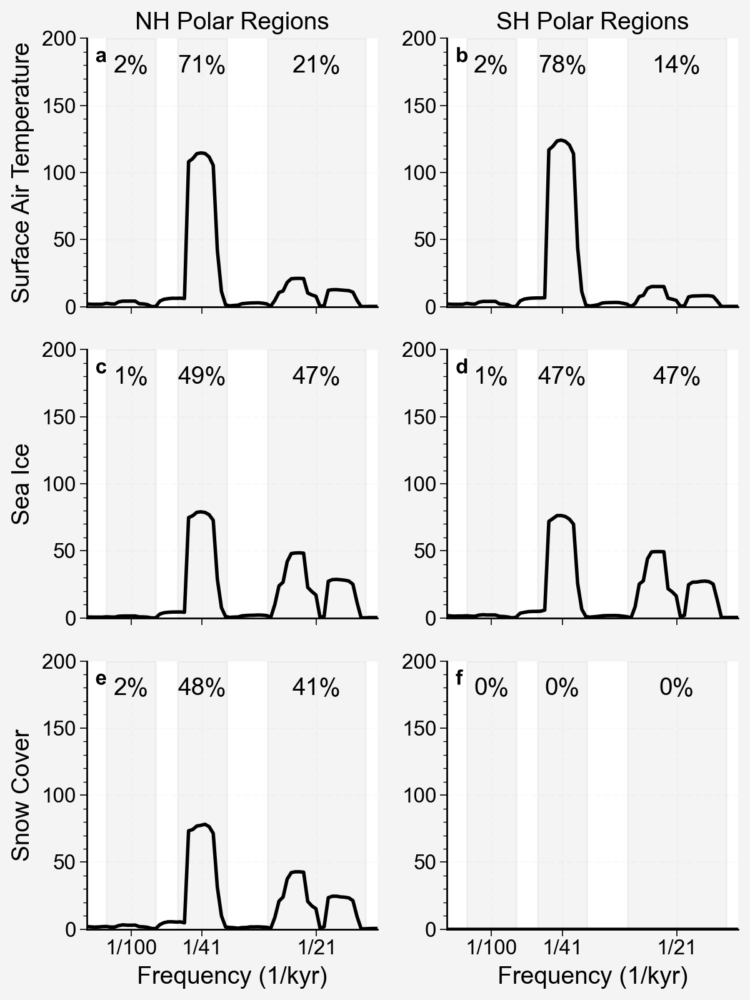

In [31]:
fig, axs = plot_variance_bands(spectral["standard"])
fig.save('paper2/f04_std_spectral_bands.png', dpi=300)

## _1c: Changes in global temperature and precipitation_

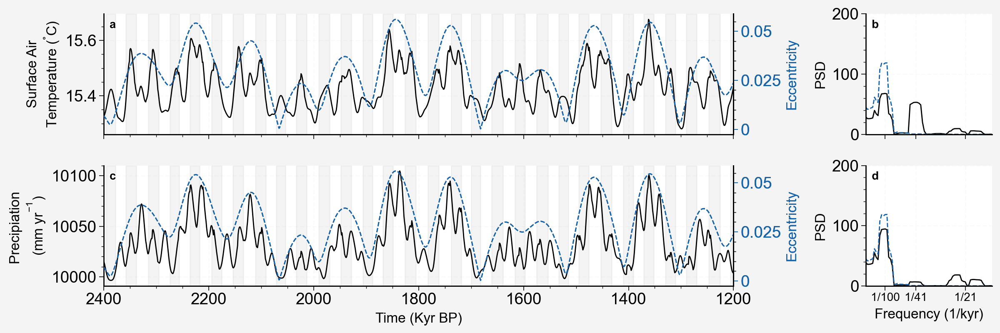

In [38]:
def plot_std_global(t1,t2):

    exp=series['standard'].copy()
    exp_psd=spectral['standard'].copy()

    # Create figure
    # =============
    
    shape = [[1,1,1,1,1,2],
             [3,3,3,3,3,4],]
    
    fig, axs = pplt.subplots(shape, figsize = (12,4), sharey = False, sharex=False, abc=True, abcbbox=False, abcloc='ul', abcsize=10)
    
    # Plot temperature
    # ================
    
    axs[0].plot(exp[f"Ta_GLB"].time[t1:t2], exp[f"Ta_GLB"].value[t1:t2], color = 'black', lw=1)
    axs[1].plot(exp_psd[f"Ta_GLB"].frequency, exp_psd[f"Ta_GLB"].amplitude, color = 'black', lw=1)
    
    axs0=axs[0].twinx()
    axs0.plot(exp[f"ecc"].time[t1:t2], exp[f"ecc"].value[t1:t2], color = 'blue9', ls = 'dashed', lw=1)
    axs[1].plot(exp_psd[f"ecc"].frequency, exp_psd[f"ecc"].amplitude, color = 'blue9', ls = 'dashed', lw=1)
    
    # Plot precipitation and snowfall
    # ===============================
    
    # precipitation
    axs[2].plot(exp[f"precip_GLB"].time[t1:t2], exp[f"precip_GLB"].value[t1:t2], color = 'black', lw=1)
    axs[3].plot(exp_psd[f"precip_GLB"].frequency, exp_psd[f"precip_GLB"].amplitude, color = 'black', lw=1)
    
    axs2=axs[2].twinx()
    axs2.plot(exp[f"ecc"].time[t1:t2], exp[f"ecc"].value[t1:t2], color = 'blue9', ls = 'dashed', lw=1)
    axs[3].plot(exp_psd[f"ecc"].frequency, exp_psd[f"ecc"].amplitude, color = 'blue9', ls = 'dashed', lw=1)
    
    # Formatting
    # ==========
    
    # time series plots
    for i in [0,2]:
        
        # fill in times of above-average obliquity
        axs[i].fill_between(exp['obl'].time[t1:t2], axs[i].get_ylim()[0], axs[i].get_ylim()[1], where = (exp['obl'].value[t1:t2] > exp['obl'].value[t1:t2].mean()), color = 'gray', alpha=0.1)
        
        # Remove tick labels for all except the last plot
        if i != 2:
            axs[i].xaxis.set_ticklabels([])
        else:
            axs[i].format(xlabel='Time (Kyr BP)')

    # spectral plots
    for i in [1, 3]:
        # x-axis
        axs[i].format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xlim = (0.001, 0.06), xticklabelsize=10)
        axs[i].xaxis.set_ticklabels([])
        axs[i].format(ylim = (0, 200), ylabel = 'PSD')
        if i == 3:
            axs[i].format(xlabel = 'Frequency (1/kyr)', xticklabels=[r'1/100','1/41','1/21'])
    
    # label fonts
    axs.format(ylabelsize=12, xlabelsize=12)
    axs0.format(ylabelsize=12, xlabelsize=12)
    axs2.format(ylabelsize=12, xlabelsize=12)

    # labels
    axs[0].format(ylabel='Surface Air\nTemperature ($^{\circ}$C)')
    axs[2].format(ylabel='Precipiation \n(mm yr$^{-1}$)')
    
    axs0.format(ylabel='Eccentricity')
    axs2.format(ylabel='Eccentricity')

    axs0.yaxis.label.set_color('blue9')
    axs2.yaxis.label.set_color('blue9')

    axs0.tick_params(axis='y', colors='blue9')
    axs2.tick_params(axis='y', colors='blue9')


    return fig, axs

# Save figure
# ===========

# 'full run'
fig, axs = plot_std_global(t1=0, t2=1400)
fig.save('paper2/fA2_std_global.png', dpi=300)

## _1d: Changes in temperature for different zones_

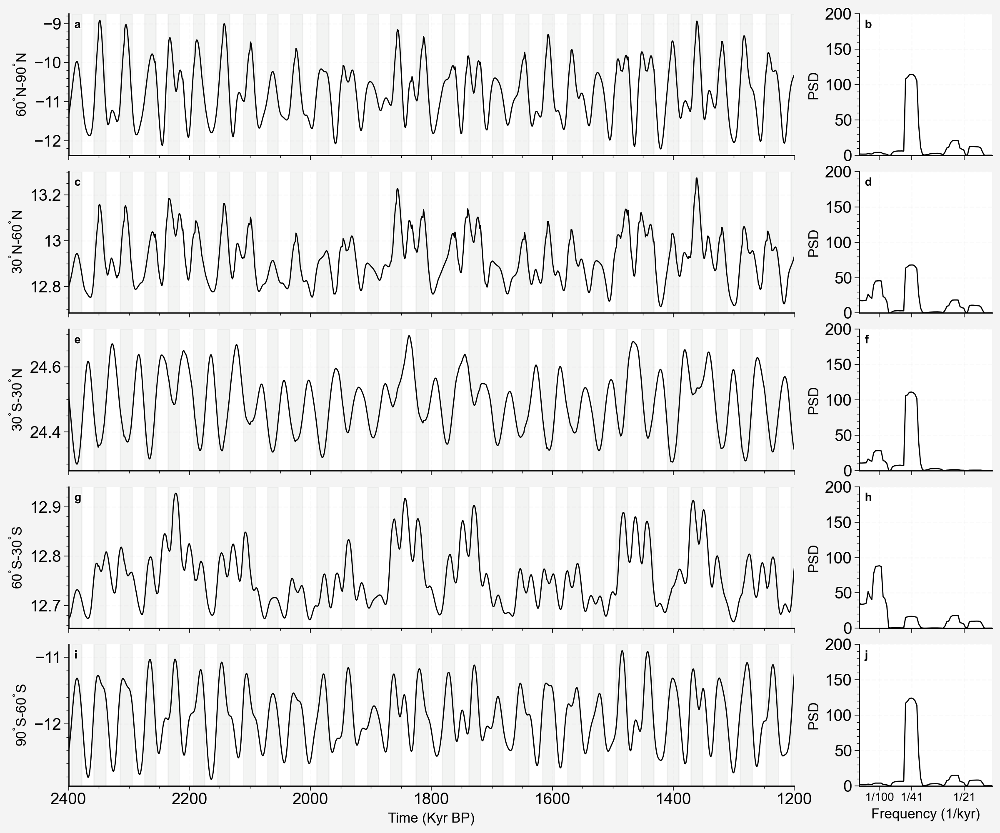

In [43]:
def plot_std_zones(t1, t2):

    std=series['standard'].copy()
    std_psd=spectral['standard'].copy()


    # Create figure
    # =============
    
    shape = [[1,1,1,1,1,1,1,1,2,2],
             [3,3,3,3,3,3,3,3,4,4],
             [5,5,5,5,5,5,5,5,6,6],
             [7,7,7,7,7,7,7,7,8,8],
             [9,9,9,9,9,9,9,9,10,10],]
    
    fig, axs = pplt.subplots(shape, figsize = (12,10), sharey = False, sharex=False, abc=True, abcbbox=False, abcloc='ul', abcsize=10, hspace=1, wspace=4)
    
    # Plot temperature
    # ================
    
    axs[0].plot(std[f"Ta_60N_90N"].time[t1:t2], std[f"Ta_60N_90N"].value[t1:t2], color = 'black', lw=1)
    axs[1].plot(std_psd[f"Ta_60N_90N"].frequency, std_psd[f"Ta_60N_90N"].amplitude, color = 'black', lw=1)

    g=axs[2].plot(std[f"Ta_30N_60N"].time[t1:t2], std[f"Ta_30N_60N"].value[t1:t2], color = 'black', lw=1)
    axs[3].plot(std_psd[f"Ta_30N_60N"].frequency, std_psd[f"Ta_30N_60N"].amplitude, color = 'black', lw=1)
    
    axs[4].plot(std[f"Ta_TRP"].time[t1:t2], std[f"Ta_TRP"].value[t1:t2], color = 'black', lw=1)
    axs[5].plot(std_psd[f"Ta_TRP"].frequency, std_psd[f"Ta_TRP"].amplitude, color = 'black', lw=1)
    
    axs[6].plot(std[f"Ta_30S_60S"].time[t1:t2], std[f"Ta_30S_60S"].value[t1:t2], color = 'black', lw=1)
    axs[7].plot(std_psd[f"Ta_30S_60S"].frequency, std_psd[f"Ta_30S_60S"].amplitude, color = 'black', lw=1)
    
    axs[8].plot(std[f"Ta_60S_90S"].time[t1:t2], std[f"Ta_60S_90S"].value[t1:t2], color = 'black', lw=1)
    axs[9].plot(std_psd[f"Ta_60S_90S"].frequency, std_psd[f"Ta_60S_90S"].amplitude, color = 'black', lw=1)

    # Formatting
    # ==========
    
    # time series plots
    for i in [0,2,4,6,8]:
        
        # fill in times of above-average obliquity
        axs[i].fill_between(std['obl'].time[t1:t2], axs[i].get_ylim()[0], axs[i].get_ylim()[1], where = (std['obl'].value[t1:t2] > std['obl'].value[t1:t2].mean()), color = 'gray', alpha=0.1, lw=1)
        
        # Remove tick labels for all except the last plot
        if i != 8:
            axs[i].xaxis.set_ticklabels([])
        else:
            axs[i].format(xlabel='Time (Kyr BP)')

    # spectral plots
    for i in [1, 3, 5,7,9]:
        # x-axis
        axs[i].format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xlim = (0.001, 0.06), xticklabelsize=10)
        axs[i].xaxis.set_ticklabels([])
        axs[i].format(ylim = (0, 200), ylabel = 'PSD')
        if i == 9:
            axs[i].format(xlabel = 'Frequency (1/kyr)', xticklabels=[r'1/100','1/41','1/21'])
    
    # label fonts
    axs.format(ylabelsize=12, xlabelsize=12)

    # labels
    axs[0].format(ylabel='60$^{\circ}$N-90$^{\circ}$N')
    axs[2].format(ylabel='30$^{\circ}$N-60$^{\circ}$N')
    axs[4].format(ylabel='30$^{\circ}$S-30$^{\circ}$N')
    axs[6].format(ylabel='60$^{\circ}$S-30$^{\circ}$S')
    axs[8].format(ylabel='90$^{\circ}$S-60$^{\circ}$S')

    return fig, axs

# Save figure
# ===========

# 'full run'
fig, axs = plot_std_zones(t1=0, t2=1400)
fig.save('paper2/fA3_std_long_zones.png', dpi=300)

# ___Changes in ZEMBA for the fixed orbital experiments___

In [44]:
# Violent Plot Data
# =================

std = series['standard']
pre = series['precession']
obl = series['obliquity']

# dictionary for violent plot data
VPFO = {} # fixed orbit experiments

# For fixed orbital experiments
for region in ['60N_90N', '60S_90S', 'GLB', 'TRP']: # for region
    for var in ['Ta', 'Ta_DJF', 'Ta_JJA', 'si_area_JJA', 'si_area_DJF', 'si_area', 'sc_area', 'surf_ocean']: # for variable
        VPFO[f"{var}_{region}"] = np.zeros((1201,3)) 
        # for each orbital experiment
        VPFO[f"{var}_{region}"][:,0] = std[f"{var}_{region}"].value       # standard
        VPFO[f"{var}_{region}"][:,1] = obl[f"{var}_{region}"].value       # obliquity  [fixed precession]
        VPFO[f"{var}_{region}"][:,2] = pre[f"{var}_{region}"].value       # precession [fixed obliquity]

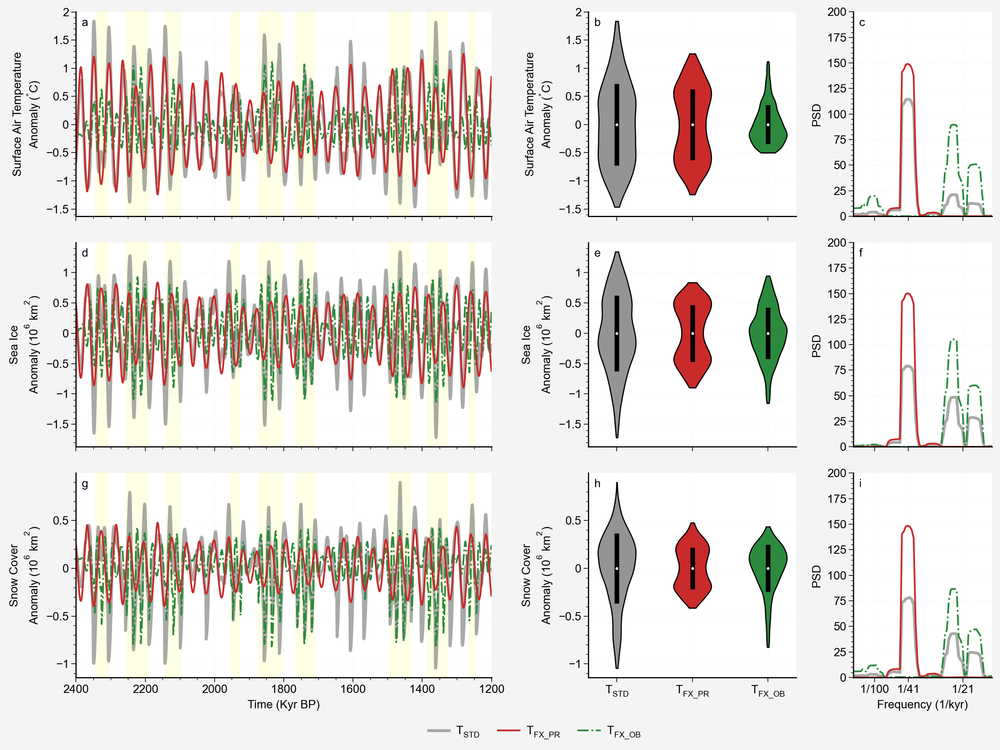

In [46]:
# Plot differences between orbital experiments (NH)
# =================================================

def plot_fixed_orbit_NH(t1,t2,region):

    # define figure
    # =============

    shape = [[1,1,1,1,1,1,2,2,2,3,3],
             [4,4,4,4,4,4,5,5,5,6,6],
             [7,7,7,7,7,7,8,8,8,9,9],]
    
    fig, axs = pplt.subplots(shape, figsize = (12,9), sharey = False, sharex=False)

    # define experiments
    std = series['standard']
    obl = series['obliquity']
    pre = series['precession']

    std_psd = spectral['standard']
    obl_psd = spectral['obliquity']
    pre_psd = spectral['precession']

    # define color and line width schemes
    stdf={'c':'gray',  'lw':2.5,'ls':'solid',  'a':0.8}
    oblf={'c':'red9',  'lw':1.5,'ls':'solid',  'a':1.0}
    pref={'c':'green9','lw':1.5,'ls':'dashdot','a':1.0}

    # list of variables to plot
    var_list = ['Ta', 'si_area', 'sc_area']
 
    # plot each variable
    ii=0
    for var in var_list:
    
        l1=axs[ii].plot(std[f"{var}_{region}"].time[t1:t2], std[f"{var}_{region}"].value[t1:t2]-std[f"{var}_{region}"].value[t1:t2].mean(), color = stdf['c'], ls = stdf['ls'], lw= stdf['lw'], alpha = stdf['a'])
        l3=axs[ii].plot(pre[f"{var}_{region}"].time[t1:t2], pre[f"{var}_{region}"].value[t1:t2]-pre[f"{var}_{region}"].value[t1:t2].mean(), color = pref['c'], ls = pref['ls'], lw= pref['lw'], alpha = pref['a'])
        l2=axs[ii].plot(obl[f"{var}_{region}"].time[t1:t2], obl[f"{var}_{region}"].value[t1:t2]-obl[f"{var}_{region}"].value[t1:t2].mean(), color = oblf['c'], ls = oblf['ls'], lw= oblf['lw'], alpha = oblf['a'])
        
        parts=axs[ii+1].violinplot(VPFO[f"{var}_{region}"]-VPFO[f"{var}_{region}"].mean(axis=0), showmeans=True, boxstd=True, facecolor=[stdf['c'], oblf['c'], pref['c']])

        l1=axs[ii+2].plot(std_psd[f"{var}_{region}"].frequency, std_psd[f"{var}_{region}"].amplitude, color = stdf['c'], ls = stdf['ls'], lw= stdf['lw'], alpha = stdf['a'])
        l3=axs[ii+2].plot(pre_psd[f"{var}_{region}"].frequency, pre_psd[f"{var}_{region}"].amplitude, color = pref['c'], ls = pref['ls'], lw= pref['lw'], alpha = pref['a'])
        l2=axs[ii+2].plot(obl_psd[f"{var}_{region}"].frequency, obl_psd[f"{var}_{region}"].amplitude, color = oblf['c'], ls = oblf['ls'], lw= oblf['lw'], alpha = oblf['a'])
        
        if ii == 6:
    
            fig.legend(handles=[l1,l2,l3], labels = [r'T$_{STD}$', r'T$_{FX\_PR}$', r'T$_{FX\_OB}$'], loc = 'b', frameon=False, ncols=4, prop = {"size": 10})
    
        ii=ii+3

    # format time-series
    for ii in [0,3,6]:
        axs[ii].fill_between(std['ecc'].time[t1:t2], axs[ii].get_ylim()[0], axs[ii].get_ylim()[1], where = (std['ecc'].value[t1:t2] > 0.035), color = 'yellow', alpha=0.1)
        if ii != 6:
            axs[ii].xaxis.set_ticklabels([])
        else:
            axs[ii].format(xlabel = 'Time (Kyr BP)')

    # format violen plots
    for ii in [1,4,7]:
        axs[ii].format(xlocator = np.arange(0, VPFO[f"{var}_{region}"].shape[1]+1), xminorlocator=[], xticklabels=[r'T$_{STD}$', r'T$_{FX\_PR}$', r'T$_{FX\_OB}$'], xticklabelsize=10)
        if ii != 7:
            axs[ii].xaxis.set_ticklabels([])
            
    # format spectral plots
    for ii in [2,5,8]:
        # x-axis
        axs[ii].format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xlim = (0.001, 0.06), xticklabelsize=10)
        axs[ii].xaxis.set_ticklabels([])
        axs[ii].format(ylim = (0, 200))
        if ii == 8:
            axs[ii].format(xlabel = 'Frequency (1/kyr)', xticklabels=[r'1/100','1/41','1/21'])
        
    # titles
    axs[0:2].format(ylabel= 'Surface Air Temperature\nAnomaly ($^{\circ}$C)')
    axs[3:5].format(ylabel= 'Sea Ice\nAnomaly (10$^{6}$ km$^{2}$)')
    axs[6:8].format(ylabel= 'Snow Cover\nAnomaly (10$^{6}$ km$^{2}$)')
    for ii in [2,5,8]:
        axs[ii].format(ylabel= 'PSD')
                
    # fonts
    axs.format(labelsize=10, ticklabelsize=10, titlesize=10,
               abc=True, abcloc='ul', abcsize=10, abcweight='normal')
    
    return fig, axs

# Save figure
# ===========

# NH
fig, axs = plot_fixed_orbit_NH(t1=0, t2=1500, region='60N_90N')
fig.save('paper2/f05_fixed_orbit_NH_polar.png', dpi=300)

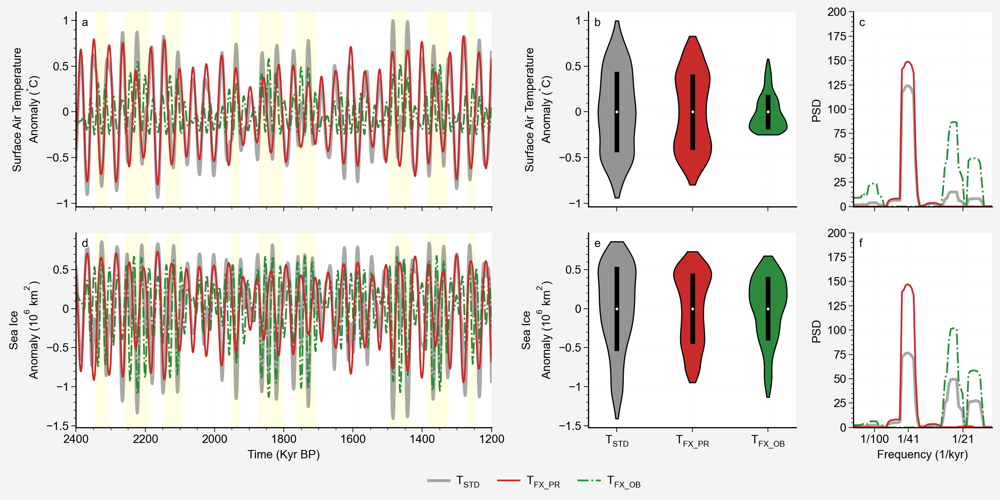

In [47]:
# Plot differences between orbital experiments (SH)
# =================================================

def plot_fixed_orbit_SH(t1,t2,region):

    # define figure
    # =============

    shape = [[1,1,1,1,1,1,2,2,2,3,3],
             [4,4,4,4,4,4,5,5,5,6,6],]
    
    fig, axs = pplt.subplots(shape, figsize = (12,6), sharey = False, sharex=False)

    # define experiments
    std = series['standard']
    obl = series['obliquity']
    pre = series['precession']

    std_psd = spectral['standard']
    obl_psd = spectral['obliquity']
    pre_psd = spectral['precession']

    # define color and line width schemes
    stdf={'c':'gray',  'lw':2.5,'ls':'solid',  'a':0.8}
    oblf={'c':'red9',  'lw':1.5,'ls':'solid',  'a':1.0}
    pref={'c':'green9','lw':1.5,'ls':'dashdot','a':1.0}

    # list of variables to plot
    var_list = ['Ta', 'si_area']
 
    # plot each variable
    ii=0
    for var in var_list:
    
        l1=axs[ii].plot(std[f"{var}_{region}"].time[t1:t2], std[f"{var}_{region}"].value[t1:t2]-std[f"{var}_{region}"].value[t1:t2].mean(), color = stdf['c'], ls = stdf['ls'], lw= stdf['lw'], alpha = stdf['a'])
        l3=axs[ii].plot(pre[f"{var}_{region}"].time[t1:t2], pre[f"{var}_{region}"].value[t1:t2]-pre[f"{var}_{region}"].value[t1:t2].mean(), color = pref['c'], ls = pref['ls'], lw= pref['lw'], alpha = pref['a'])
        l2=axs[ii].plot(obl[f"{var}_{region}"].time[t1:t2], obl[f"{var}_{region}"].value[t1:t2]-obl[f"{var}_{region}"].value[t1:t2].mean(), color = oblf['c'], ls = oblf['ls'], lw= oblf['lw'], alpha = oblf['a'])
        
        parts=axs[ii+1].violinplot(VPFO[f"{var}_{region}"]-VPFO[f"{var}_{region}"].mean(axis=0), showmeans=True, boxstd=True, facecolor=[stdf['c'], oblf['c'], pref['c']])

        l1=axs[ii+2].plot(std_psd[f"{var}_{region}"].frequency, std_psd[f"{var}_{region}"].amplitude, color = stdf['c'], ls = stdf['ls'], lw= stdf['lw'], alpha = stdf['a'])
        l3=axs[ii+2].plot(pre_psd[f"{var}_{region}"].frequency, pre_psd[f"{var}_{region}"].amplitude, color = pref['c'], ls = pref['ls'], lw= pref['lw'], alpha = pref['a'])
        l2=axs[ii+2].plot(obl_psd[f"{var}_{region}"].frequency, obl_psd[f"{var}_{region}"].amplitude, color = oblf['c'], ls = oblf['ls'], lw= oblf['lw'], alpha = oblf['a'])
        
        if ii == 3:
    
            fig.legend(handles=[l1,l2,l3], labels = [r'T$_{STD}$', r'T$_{FX\_PR}$', r'T$_{FX\_OB}$'], loc = 'b', frameon=False, ncols=4, prop = {"size": 10})
    
        ii=ii+3

    # format time-series
    for ii in [0,3]:
        axs[ii].fill_between(std['ecc'].time[t1:t2], axs[ii].get_ylim()[0], axs[ii].get_ylim()[1], where = (std['ecc'].value[t1:t2] > 0.035), color = 'yellow', alpha=0.1)
        if ii != 3:
            axs[ii].xaxis.set_ticklabels([])
        else:
            axs[ii].format(xlabel = 'Time (Kyr BP)')

    # format violen plots
    for ii in [1,4]:
        axs[ii].format(xlocator = np.arange(0, VPFO[f"{var}_{region}"].shape[1]+1), xminorlocator=[], xticklabels=[r'T$_{STD}$', r'T$_{FX\_PR}$', r'T$_{FX\_OB}$'], xticklabelsize=10)
        if ii != 4:
            axs[ii].xaxis.set_ticklabels([])
            
    # format spectral plots
    for ii in [2,5]:
        # x-axis
        axs[ii].format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xlim = (0.001, 0.06), xticklabelsize=10)
        axs[ii].xaxis.set_ticklabels([])
        axs[ii].format(ylim = (0, 200))
        if ii == 5:
            axs[ii].format(xlabel = 'Frequency (1/kyr)', xticklabels=[r'1/100','1/41','1/21'])
        
    # titles
    axs[0:2].format(ylabel= 'Surface Air Temperature\nAnomaly ($^{\circ}$C)')
    axs[3:5].format(ylabel= 'Sea Ice\nAnomaly (10$^{6}$ km$^{2}$)')
    for ii in [2,5]:
        axs[ii].format(ylabel= 'PSD')
                
    # fonts
    axs.format(labelsize=10, ticklabelsize=10, titlesize=10,
               abc=True, abcloc='ul', abcsize=10, abcweight='normal')
    
    return fig, axs

# Save figure
# ===========

# NH
fig, axs = plot_fixed_orbit_SH(t1=0, t2=1500, region='60S_90S')
fig.save('paper2/fA4_fixed_orbit_SH_polar.png', dpi=300)

In [49]:
from scipy.signal import find_peaks

# Find maximim and minima
# =======================

obl = series['obliquity']
pre = series['precession']
std = series['standard']

# anomalies
obl_anomaly = obl['SSI_65N'].value-obl['SSI_65N'].value.mean()
pre_anomaly = pre['SSI_65N'].value-pre['SSI_65N'].value.mean()
std_anomaly = std['SSI_65N'].value-std['SSI_65N'].value.mean()

# maximima
obl_peaks, _ = find_peaks(obl_anomaly, height=0)
pre_peaks, _ = find_peaks(pre_anomaly, height=0)
std_peaks, _ = find_peaks(std_anomaly, height=0)
obl_peaks    = obl_peaks.astype(int)
pre_peaks    = pre_peaks.astype(int)
std_peaks    = std_peaks.astype(int)

# minima
obl_troughs, _ = find_peaks(-obl_anomaly, height=0)
pre_troughs, _ = find_peaks(-pre_anomaly, height=0)
std_troughs, _ = find_peaks(-std_anomaly, height=0)
obl_troughs    = obl_troughs.astype(int)
pre_troughs    = pre_troughs.astype(int)
std_troughs    = std_troughs.astype(int)

# remove low eccentricity values for precession
#ecc = pre['e'].value
#ecc_idx     = np.where(ecc[pre_peaks]>0.025)
#ecc_idx2    = np.where(ecc[pre_troughs]>0.025)
#pre_peaks   = pre_peaks[ecc_idx]
#pre_troughs = pre_troughs[ecc_idx2]

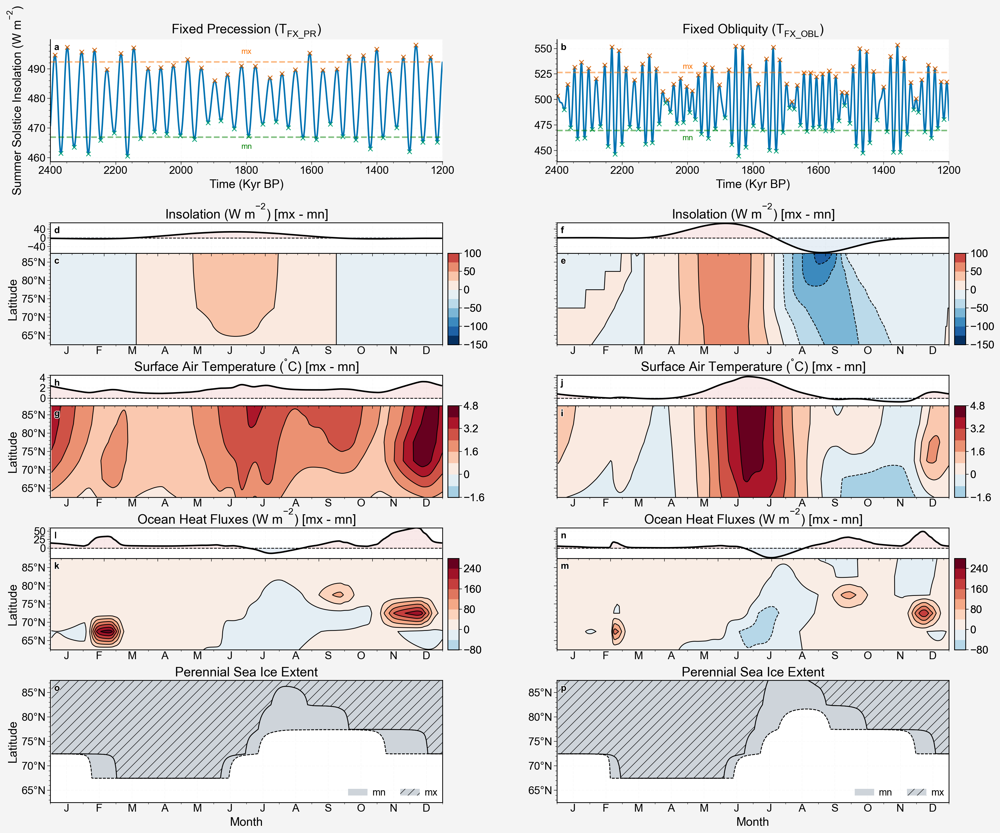

In [51]:
# PLOT SEASONAL DIFFERENCES FOR EXTREMES
# ======================================

shape = [[1,1,1,1,0,2,2,2,2],
         [1,1,1,1,0,2,2,2,2],
         [1,1,1,1,0,2,2,2,2],
         [1,1,1,1,0,2,2,2,2],
         [0,0,0,0,0,0,0,0,0],
         [0,0,0,0,0,0,0,0,0],
         [4,4,4,4,0,6,6,6,6],
         [3,3,3,3,0,5,5,5,5],
         [3,3,3,3,0,5,5,5,5],
         [3,3,3,3,0,5,5,5,5],
         [0,0,0,0,0,0,0,0,0],
         [8,8,8,8,0,10,10,10,10],
         [7,7,7,7,0,9,9,9,9],
         [7,7,7,7,0,9,9,9,9],
         [7,7,7,7,0,9,9,9,9],
         [0,0,0,0,0,0,0,0,0],
         [12,12,12,12,0,14,14,14,14],
         [11,11,11,11,0,13,13,13,13],
         [11,11,11,11,0,13,13,13,13],
         [11,11,11,11,0,13,13,13,13],
         [0,0,0,0,0,0,0,0,0],
         [15,15,15,15,0,16,16,16,16],
         [15,15,15,15,0,16,16,16,16],
         [15,15,15,15,0,16,16,16,16],
         [15,15,15,15,0,16,16,16,16],
        ]

# define figure
fig, axs = pplt.subplots(shape, figsize=(18,15), sharex=False, sharey=False, space=0, abc=True, abcloc='ul',abcsize=12)

days, lats = np.meshgrid(np.arange(1, 366, 1), Var["lat"])

obl = series['obliquity']
pre = series['precession']
std = series['standard']


# plot insolation maxima and minima 
# =================================

# obliquity (fixed precession)
axs[0].plot(obl['SSI_65N'].time, obl['SSI_65N'].value)
axs[0].plot(obl['SSI_65N'].time[obl_peaks], obl['SSI_65N'].value[obl_peaks], "x")
axs[0].plot(obl['SSI_65N'].time[obl_troughs], obl['SSI_65N'].value[obl_troughs], "x")
axs[0].axhline(obl['SSI_65N'].value[obl_peaks].mean(), color = 'orange', linestyle = 'dashed', alpha=0.5) 
axs[0].axhline(obl['SSI_65N'].value[obl_troughs].mean(), color = 'green', linestyle = 'dashed', alpha=0.5) 
axs[0].text(1800, 495, 'mx', color = 'orange', fontsize=10, horizontalalignment='center') 
axs[0].text(1800, 463, 'mn', color = 'green', fontsize=10, horizontalalignment='center') 

# precession (fixed obliquity)
axs[1].plot(pre['SSI_65N'].time, pre['SSI_65N'].value)
axs[1].plot(pre['SSI_65N'].time[pre_peaks], pre['SSI_65N'].value[pre_peaks], "x")
axs[1].plot(pre['SSI_65N'].time[pre_troughs], pre['SSI_65N'].value[pre_troughs], "x")
axs[1].axhline(pre['SSI_65N'].value[pre_peaks].mean(), color = 'orange', linestyle = 'dashed', alpha=0.5) 
axs[1].axhline(pre['SSI_65N'].value[pre_troughs].mean(), color = 'green', linestyle = 'dashed', alpha=0.5) 
axs[1].text(2000, 530, 'mx', color = 'orange', fontsize=10, horizontalalignment='center') 
axs[1].text(2000, 460, 'mn', color = 'green',  fontsize=10, horizontalalignment='center') 

# plot contour plots of maxima minum minima
# =========================================

# index for NH polar regions
indexa = idx['60N_90N']
indexo = idxo['60N_90N']

# limits
vlim_I=[-150, 120]   # insolation
vlim_TA=[-2, 5]      # temperature
vlim_SO=[-100, 300]  # surface ocean heat fluxes
vlim_SI=[-100, 0]    # sea ice

# plot 
for ii, var, vlim in zip([2,6,10,14], ['I', 'Ta', 'surf_ocean', 'si_fraction'], [vlim_I, vlim_TA, vlim_SO, vlim_SI]):

    # PLOT CONTOURS
    # =============
    
    # choice of index
    if var == 'surf_ocean' or var == 'si_fraction':
        index=indexo
    else:
        index=indexa

    # precession maxima and minima
    pre_mx = transient_experiment['precession'][f"{var}_rw"][pre_peaks].mean(axis=0)[index,:]
    pre_mn = transient_experiment['precession'][f"{var}_rw"][pre_troughs].mean(axis=0)[index,:]

    # obliquity maxima and minima
    obl_mx = transient_experiment['obliquity'][f"{var}_rw"][obl_peaks].mean(axis=0)[index,:]
    obl_mn = transient_experiment['obliquity'][f"{var}_rw"][obl_troughs].mean(axis=0)[index,:]

    # if sea ice - convert fraction to percentage
    if var == 'si_fraction':
        pre_mx = pre_mx*100
        pre_mn = pre_mn*100
        obl_mx = obl_mx*100
        obl_mn = obl_mn*100

    # plot maxima minus minima anomalies
    if var == 'I' or var == 'Ta' or var == 'surf_ocean':
        axs[ii].contourf(days[index,:], lats[index,:], obl_mx-obl_mn, vmin=vlim[0], vmax=vlim[1], lw=1, colorbar='r')
        axs[ii+2].contourf(days[index,:], lats[index,:], pre_mx-pre_mn, vmin=vlim[0], vmax=vlim[1], lw=1, colorbar='r')

    # if sea ice fraction, instead plot permanent sea ice cover lines
    elif var == 'si_fraction': 
        
        # obliquity 
        axs[ii].contourf(days[28:,:], lats[28:,:], transient_experiment['obliquity']['si_fraction_rw'][obl_troughs].mean(axis=0)[28:], lw=1, levels=[0.99,0.99001,1.], c='gray4', ls = 'dashed')
        axs[ii].contourf(days[28:,:], lats[28:,:], transient_experiment['obliquity']['si_fraction_rw'][obl_peaks].mean(axis=0)[28:], lw=1, levels=[0.99,0.99001,1.], c='gray4',hatches=['//'])

        # precession
        l1=axs[ii+1].contourf(days[28:,:], lats[28:,:], transient_experiment['precession']['si_fraction_rw'][pre_troughs].mean(axis=0)[28:], lw=1, levels=[0.99,0.99001,1.], c='gray4', ls = 'dashed')
        l2=axs[ii+1].contourf(days[28:,:], lats[28:,:], transient_experiment['precession']['si_fraction_rw'][pre_peaks].mean(axis=0)[28:], lw=1, levels=[0.99,0.99001,1.], c='gray4',hatches=['//'])

        # legend
        axs[ii].legend(handles=[l1,l2], labels=['mn', 'mx'], ncols=2, loc='lr', frameon=False)
        axs[ii+1].legend(handles=[l1,l2], labels=['mn', 'mx'], ncols=2, loc='lr', frameon=False)

    # PLOT LINES
    # ==========

    if var == 'I' or var == 'Ta' or var == 'surf_ocean':
    
        # weights for averaging
        if var == 'I' or var == 'Ta':
            obl_avg = np.average(obl_mx-obl_mn, axis=0, weights=Var['sarea'][index])
            pre_avg = np.average(pre_mx-pre_mn, axis=0, weights=Var['sarea'][index])
        
        elif var == 'surf_ocean':
            obl_avg = np.average(obl_mx-obl_mn, axis=0, weights=Var['oarea'][index])
            pre_avg = np.average(pre_mx-pre_mn, axis=0, weights=Var['oarea'][index])

        # plot obliquity average
        axs[ii+1].plot(np.arange(0, 365), obl_avg, c='black')
        axs[ii+1].fill_between(np.arange(0, 365), np.zeros((365)), obl_avg, where = (obl_avg>0), c='red9', alpha=0.1)
        axs[ii+1].fill_between(np.arange(0, 365), np.zeros((365)), obl_avg, where = (obl_avg<0), c='blue9', alpha=0.1)

        # plot precession average
        pre_avg = np.average(pre_mx-pre_mn, axis=0, weights=Var['oarea'][index])
        axs[ii+3].plot(np.arange(0, 365), pre_avg, c='black')
        axs[ii+3].fill_between(np.arange(0, 365), np.zeros((365)), pre_avg, where = (pre_avg>0), c='red9', alpha=0.1)
        axs[ii+3].fill_between(np.arange(0, 365), np.zeros((365)), pre_avg, where = (pre_avg<0), c='blue9', alpha=0.1)

        # some formatting
        axs[ii+1].xaxis.set_ticklabels([])
        axs[ii+3].xaxis.set_ticklabels([])

    # additional formatting
    axs[ii].spines[['top', 'right']].set_visible(True)
    axs[ii+1].spines[['top', 'right']].set_visible(True)
    if var == 'I' or var == 'Ta' or var == 'surf_ocean':
        axs[ii+2].spines[['top', 'right']].set_visible(True)
        axs[ii+3].spines[['top', 'right']].set_visible(True)


# FORMATTING
# ==========


# y limits for line plots
for i in [3,5]:
    axs[i].format(ylim=(-70,70), ylocator=[-40,0,40])
    axs[i].hlines(0,0,365, ls='dashed', lw=1, c='black')

for i in [7,9]:
    axs[i].format(ylim=(-1.5,4.5), ylocator=[0,2,4])
    axs[i].hlines(0,0,365, ls='dashed', lw=1, c='black')

for i in [11,13]:
    axs[i].format(ylim=(-30,60), ylocator=[0,25,50])
    axs[i].hlines(0,0,365, ls='dashed', lw=1, c='black')

# contour plots
for i in [2,4,6,8,10,12,14,15]: 

    axs[i].format(

    # x-axis
    xlim=(0, 365), xlocator=np.linspace(30, 365, 12) - 15,
    xminorlocator=np.linspace(0, 365, 13), xticklabels=["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"],

    # y-axis
    ylim=(62.5, 87.5), ylocator=[65, 70, 75, 80, 85] ,yformatter='deglat',
    yminorlocator=np.arange(63, 87+1))
    axs[i].tick_params(axis='x', length=0)
        
    if i in [2,6,10,14]:
        axs[i].format(ylabel='Latitude')

    if i in [14,15]:
        axs[i].format(xlabel='Month')

    if i in [4,8,12]:
        axs[i].yaxis.set_ticklabels([])
        axs[i+1].yaxis.set_ticklabels([])
    if i in [12]:
        axs[i].yaxis.set_ticklabels([])


# LABELS AND TITLES
# =================

for i in [0,1]:
    if i == 0:
        axs[i].format(ylabel='Summer Solstice Insolation (W m$^{-2}$)')
axs[0].set_title('Fixed Precession (T$_{FX\_PR}$)')
axs[1].set_title('Fixed Obliquity (T$_{FX\_OBL}$)')

for i in [3,5]:
    axs[i].set_title('Insolation (W m$^{-2}$) [mx - mn]')

for i in [7,9]:
    axs[i].set_title('Surface Air Temperature ($^{\circ}$C) [mx - mn]')

for i in [11,13]:
    axs[i].set_title('Ocean Heat Fluxes (W m$^{-2}$) [mx - mn]')

for i in [14,15]:
    axs[i].set_title('Perennial Sea Ice Extent')

axs[0:2].format(xlabel='Time (Kyr BP)')

# SAVE FIGURE

fig.save('paper2/f06_seasonal_extremes.png', dpi=300)

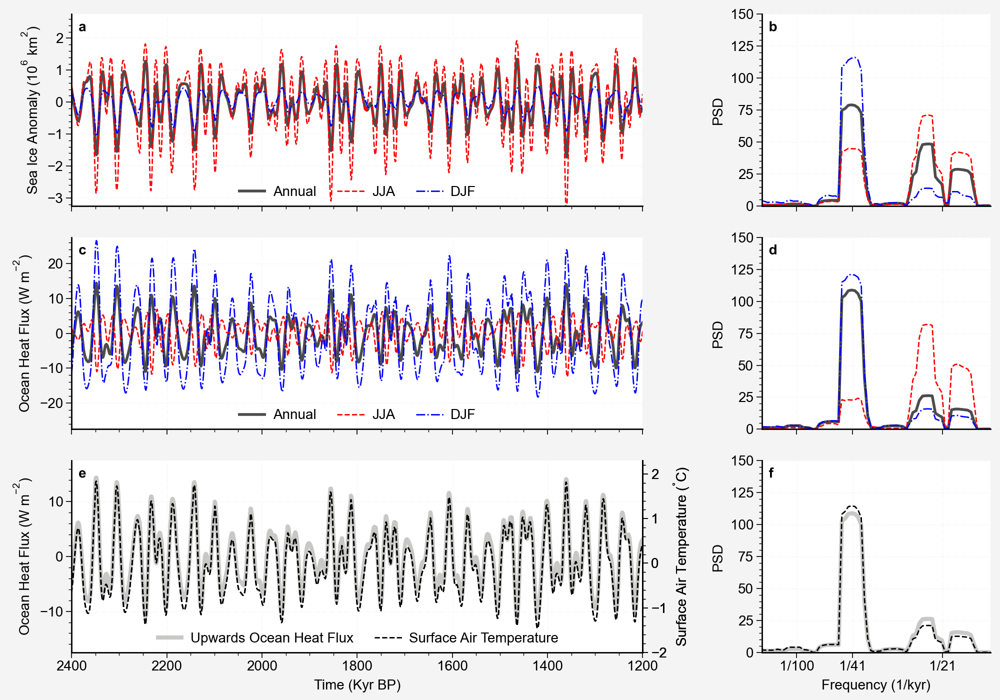

In [58]:
# PLOT SEA ICE, OHF AND SAT FOR STANDARD EXPERIMENT
# =================================================

std     = series['standard']
std_psd = spectral['standard']


shape = [[1,1,1,1,1,2,2],
         [3,3,3,3,3,4,4],
         [5,5,5,5,5,6,6],]

fig, axs = pplt.subplots(shape, figsize=(10,7), sharex=False, sharey=False, abc=True, abcloc='ul', abcsize=10)

for ii, var in zip([0,2], ['si_area', 'surf_ocean']):

    # time-series
    l1=axs[ii].plot(std[f"{var}_60N_90N"].time, std[f'{var}_60N_90N'].value-std[f"{var}_60N_90N"].value.mean(), lw=2, color='black', alpha=0.7)
    l2=axs[ii].plot(std[f"{var}_JJA_60N_90N"].time, std[f"{var}_JJA_60N_90N"].value-std[f"{var}_JJA_60N_90N"].value.mean(), lw=1, color='red', alpha=1, ls='dashed')
    l3=axs[ii].plot(std[f"{var}_DJF_60N_90N"].time, std[f"{var}_DJF_60N_90N"].value-std[f"{var}_DJF_60N_90N"].value.mean(), lw=1, color='blue', alpha=1, ls='dashdot')

    axs[ii].legend(handles=[l1,l2,l3], labels=['Annual', 'JJA', 'DJF'], ncols=3, frameon=False, loc='lc', prop={'size': 10})
   
    # spectral plot
    axs[ii+1].plot(std_psd[f"{var}_60N_90N"].frequency, std_psd[f'{var}_60N_90N'].amplitude, lw=2, color='black', alpha=0.7)
    axs[ii+1].plot(std_psd[f"{var}_JJA_60N_90N"].frequency, std_psd[f"{var}_JJA_60N_90N"].amplitude, lw=1, color='red', alpha=1, ls='dashed')
    axs[ii+1].plot(std_psd[f"{var}_DJF_60N_90N"].frequency, std_psd[f"{var}_DJF_60N_90N"].amplitude, lw=1, color='blue', alpha=1, ls='dashdot')
    axs[ii+1].format(ylabel='PSD', xlabelsize=15, xminorlocator=[], xlocator=[1/100, 1/41, 1/21], xticklabels=[r'1/100','1/41','1/21'],
                 xlim = (0.001, 0.06), ylim = (0,150))


# compare winter sea ice, temperature and ocean heat fluxes
# =========================================================

l1=axs[4].plot(std[f"surf_ocean_60N_90N"].time, std[f"surf_ocean_60N_90N"].value-std[f"surf_ocean_60N_90N"].value.mean(), lw=3, color='gray', alpha=0.5, ls = 'solid')

axs44=axs[4].twinx()
l2=axs44.plot(std[f"Ta_60N_90N"].time, std[f"Ta_60N_90N"].value-std[f"Ta_60N_90N"].value.mean(), lw=1, color='black', alpha=1, ls='dashed')

axs[4].legend(handles=[l1,l2], labels=['Upwards Ocean Heat Flux', 'Surface Air Temperature'], ncols=2, frameon=False, loc='lc', prop={'size': 10})
   

axs[5].plot(std_psd[f"surf_ocean_60N_90N"].frequency, std_psd[f"surf_ocean_60N_90N"].amplitude, lw=3, color='gray', alpha=0.5, ls = 'solid')
axs[5].plot(std_psd[f"Ta_60N_90N"].frequency, std_psd[f"Ta_60N_90N"].amplitude, lw=1, color='black', alpha=1, ls='dashed')

axs[5].format(ylabel='PSD', xlabel = 'Frequency (1/kyr)', xlabelsize=15, xminorlocator=[], xlocator=[1/100, 1/41, 1/21], xticklabels=[r'1/100','1/41','1/21'],
                 xlim = (0.001, 0.06), ylim = (0,150))

axs[4].format(xlabel='Time (Kyr BP)')

axs[0].format(ylim=(-3.25, 2.75), ylabel = 'Sea Ice Anomaly (10$^{6}$ km$^{2}$)')
axs[2].format(ylim=(-27.5, 27.5),   ylabel = 'Ocean Heat Flux (W m$^{-2}$)')
axs[4].format(ylim=(-17.5, 17.5),   ylabel = 'Ocean Heat Flux (W m$^{-2}$)')
axs44.format(ylim=(-2,2.3),      ylabel = 'Surface Air Temperature ($^{\circ}$C)')
for ii in [0,2]:
    axs[ii].xaxis.set_ticklabels([])
    axs[ii+1].xaxis.set_ticklabels([])

axs.format(labelsize=10, ticklabelsize=10)
axs44.format(labelsize=10, ticklabelsize=10)

fig.save('paper2/f07_ocean_heat_fluxes.png', dpi=300)

# ___Changes in ZEMBA for the fixed albedo experiments___

In [59]:
# Violent Plot Data
# =================

# dictionary for violent plot data
VPFA = {} # fixed albedo experiments

# For fixed albedo experiments
for region in ['60N_90N', '60S_90S', 'GLB', 'TRP']: # for region
    for var in ['Ta', 'si_area', 'sc_area']: # for variable
        VPFA[f"{var}_{region}"] = np.zeros((1201,4)) 
        # for each orbital experiment
        VPFA[f"{var}_{region}"][:,0] = series['standard'][f"{var}_{region}"].value       # standard
        VPFA[f"{var}_{region}"][:,1] = series['fxla'][f"{var}_{region}"].value      # fixed sea ice
        VPFA[f"{var}_{region}"][:,2] = series['fxoa'][f"{var}_{region}"].value      # fixed snow cover
        VPFA[f"{var}_{region}"][:,3] = series['fxoa_fxla'][f"{var}_{region}"].value # fixed sea ice and snow cover

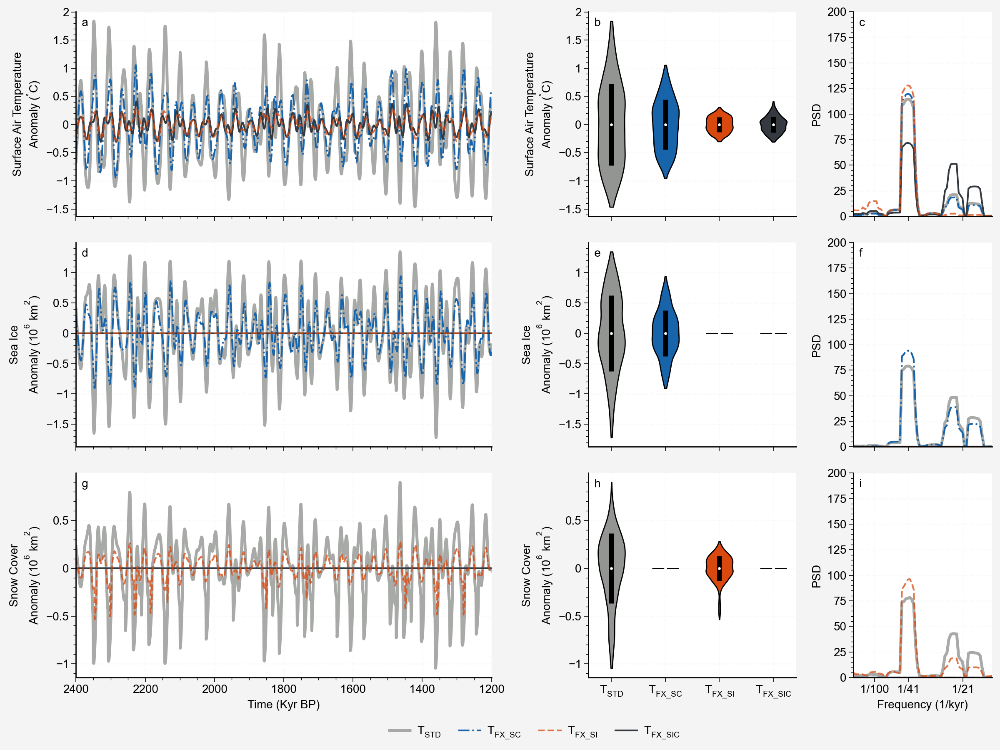

In [61]:
def plot_fixed_albedo_NH(t1,t2,region):

    # define figure
    # =============
    
    shape = [[1,1,1,1,1,1,2,2,2,3,3],
             [4,4,4,4,4,4,5,5,5,6,6],
             [7,7,7,7,7,7,8,8,8,9,9],]

    fig, axs = pplt.subplots(shape, figsize = (12,9), sharey = False, sharex=False, )

    # define color and line width schemes
    stdf={'c':'gray',  'lw':2.5,'ls':'solid',  'a':0.8}
    fxlaf={'c':'blue9',  'lw':1.5,'ls':'dashdot',  'a':1.0}
    fxoaf={'c':'orange9','lw':1.5,'ls':'dashed','a':0.75}
    fxoa_fxlaf={'c':'gray8','lw':1.5,'ls':'solid','a':1.0}

    # list of variables to plot
    var_list = ['Ta', 'si_area', 'sc_area']

    # plot each variable
    ii=0
    for var in ['Ta', 'si_area', 'sc_area']:
    
        l1=axs[ii].plot(series['standard'][f"{var}_{region}"].time[t1:t2], series['standard'][f"{var}_{region}"].value[t1:t2]-series['standard'][f"{var}_{region}"].value[t1:t2].mean(), color = stdf['c'], ls = stdf['ls'], lw= stdf['lw'], alpha = stdf['a'])
        l2=axs[ii].plot(series['fxla'][f"{var}_{region}"].time[t1:t2], series['fxla'][f"{var}_{region}"].value[t1:t2]-series['fxla'][f"{var}_{region}"].value[t1:t2].mean(), color = fxlaf['c'], ls = fxlaf['ls'], lw= fxlaf['lw'], alpha = fxlaf['a'])
        l4=axs[ii].plot(series['fxoa_fxla'][f"{var}_{region}"].time[t1:t2], series['fxoa_fxla'][f"{var}_{region}"].value[t1:t2]-series['fxoa_fxla'][f"{var}_{region}"].value[t1:t2].mean(), color = fxoa_fxlaf['c'], ls = fxoa_fxlaf['ls'], lw= fxoa_fxlaf['lw'], alpha = fxoa_fxlaf['a'])
        l3=axs[ii].plot(series['fxoa'][f"{var}_{region}"].time[t1:t2], series['fxoa'][f"{var}_{region}"].value[t1:t2]-series['fxoa'][f"{var}_{region}"].value[t1:t2].mean(), color = fxoaf['c'], ls = fxoaf['ls'], lw= fxoaf['lw'], alpha = fxoaf['a'])
        
        parts=axs[ii+1].violinplot(VPFA[f"{var}_{region}"]-VPFA[f"{var}_{region}"].mean(axis=0), showmeans=True, boxstd=True, facecolor=[stdf['c'], fxlaf['c'], fxoaf['c'], fxoa_fxlaf['c']])

        l1=axs[ii+2].plot(spectral['standard'][f"{var}_{region}"].frequency, spectral['standard'][f"{var}_{region}"].amplitude, color = stdf['c'], ls = stdf['ls'], lw= stdf['lw'], alpha = stdf['a'])
        l2=axs[ii+2].plot(spectral['fxla'][f"{var}_{region}"].frequency, spectral['fxla'][f"{var}_{region}"].amplitude, color = fxlaf['c'], ls = fxlaf['ls'], lw= fxlaf['lw'], alpha = fxlaf['a'])
        l4=axs[ii+2].plot(spectral['fxoa_fxla'][f"{var}_{region}"].frequency, spectral['fxoa_fxla'][f"{var}_{region}"].amplitude, color = fxoa_fxlaf['c'], ls = fxoa_fxlaf['ls'], lw= fxoa_fxlaf['lw'], alpha = fxoa_fxlaf['a'])
        l3=axs[ii+2].plot(spectral['fxoa'][f"{var}_{region}"].frequency, spectral['fxoa'][f"{var}_{region}"].amplitude, color = fxoaf['c'], ls = fxoaf['ls'], lw= fxoaf['lw'], alpha = fxoaf['a'])
        
        if ii == 6:
    
            fig.legend(handles=[l1,l2,l3,l4], labels = [r'T$_{STD}$', r'T$_{FX\_SC}$', r'T$_{FX\_SI}$', r'T$_{FX\_SIC}$' ], loc = 'b', frameon=False, ncols=4, prop = {"size": 10})
    
        ii=ii+3

    # format time-series
    for ii in [0,3,6]:
        #axs[ii].fill_between(series['standard']['ecc'].time[t1:t2], axs[ii].get_ylim()[0], axs[ii].get_ylim()[1], where = (series['standard']['ecc'].value[t1:t2] > 0.035), color = 'yellow', alpha=0.1)
        if ii != 6:
            axs[ii].xaxis.set_ticklabels([])
        else:
            axs[ii].format(xlabel = 'Time (Kyr BP)')

    # format violen plots
    for ii in [1,4,7]:
        axs[ii].format(xlocator = np.arange(0, VPFA[f"{var}_{region}"].shape[1]+1), xminorlocator=[], xticklabels=[r'T$_{STD}$', r'T$_{FX\_SC}$', r'T$_{FX\_SI}$', r'T$_{FX\_SIC}$' ], xticklabelsize=10)
        if ii != 7:
            axs[ii].xaxis.set_ticklabels([])
            
    # format spectral plots
    for ii in [2,5,8]:
        # x-axis
        axs[ii].format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xlim = (0.001, 0.06), xticklabelsize=10)
        axs[ii].xaxis.set_ticklabels([])
        axs[ii].format(ylim = (0, 200))
        if ii == 8:
            axs[ii].format(xlabel = 'Frequency (1/kyr)', xticklabels=[r'1/100','1/41','1/21'])

    # titles
    axs[0:2].format(ylabel= 'Surface Air Temperature\nAnomaly ($^{\circ}$C)')
    axs[3:5].format(ylabel= 'Sea Ice\nAnomaly (10$^{6}$ km$^{2}$)')
    axs[6:9].format(ylabel= 'Snow Cover\nAnomaly (10$^{6}$ km$^{2}$)')
    for ii in [2,5,8]:
        axs[ii].format(ylabel= 'PSD')
                     
    # fonts
    axs.format(labelsize=10, ticklabelsize=10, titlesize=10,
               abc=True, abcloc='ul', abcsize=10, abcweight='normal')
    
    return fig, axs

# Save figure
# ===========

# NH
fig, axs = plot_fixed_albedo_NH(t1=0, t2=1500, region='60N_90N')
fig.save('paper2/f08_fixed_albedo_NH_polar.png', dpi=300)

# ___Comparison of temperatures with different summer insolation metrics and orbital parameters.___

## _Changes in polar temperature with various summer insolation metrics_

Compares surface air temperature variability averaged across the polar latitudes versus different insolation metrics at 65 N/S including summer solstice insolation, average caloric summer-half year insolation and integrated summer insolation above 275 W m2

First: Northern Hemisphere.

Evaluating association on surrogate pairs: 100%|█████████████████████████████████| 1000/1000 [00:00<00:00, 1196.94it/s]


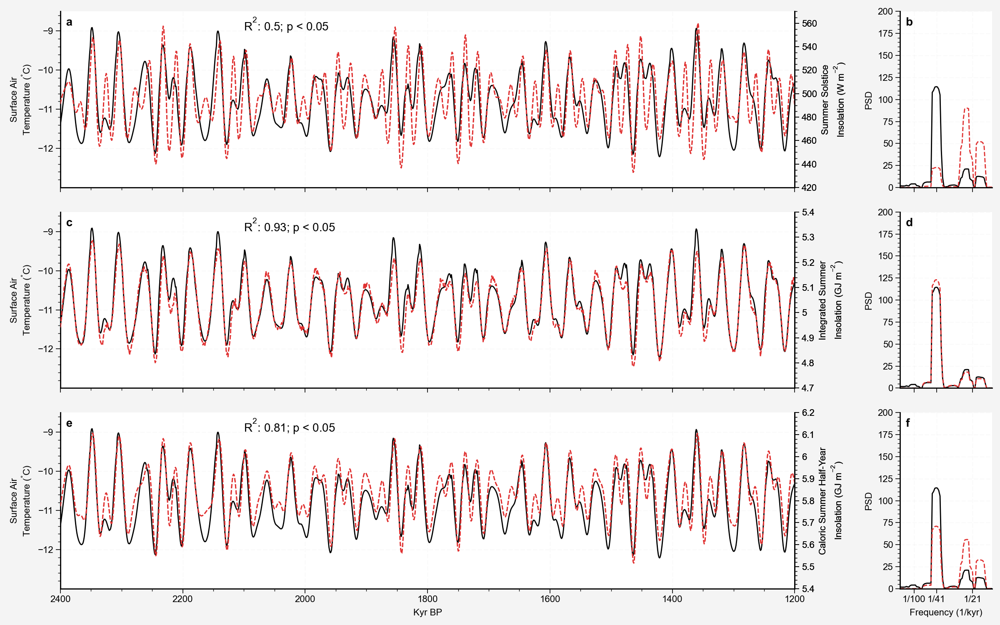

In [8]:
std = series['standard']
std_psd = spectral['standard']

# Calculate correlation of temperature with insolation metrics
# ============================================================

corr_ss  = std['Ta_60N_90N'].correlation(std['SSI_65N'])     # summer solstice
corr_isi = std['Ta_60N_90N'].correlation(std['ISI_65N'])     # integrated summer insolation
corr_clr = std['Ta_60N_90N'].correlation(std['CSH_65N'])     # caloric half-year

# R2
R2_ss  = np.round((corr_ss.r**2),2)
R2_isi = np.round((corr_isi.r**2),2)
R2_clr = np.round((corr_clr.r**2),2)

# Create figure
# =============

shape    = [[1,1,1,1,1,1,1,1,2],[3,3,3,3,3,3,3,3,4],[5,5,5,5,5,5,5,5,6],]
fig, axs = pplt.subplots(shape, figsize = (12, 7.5), sharey=False, sharex=False, abc=True, abcbbox=False, abcloc='ul', abcsize=10)

# Plot surface air temperature
# ============================

# time series
for i in [0,2,4]:
    l1=axs[i].plot(std['Ta_60N_90N'].time, std['Ta_60N_90N'].value, lw =1, c='black')  # NH
    axs[i+1].plot(std_psd['Ta_60N_90N'].frequency, std_psd['Ta_60N_90N'].amplitude, lw =1, c='black') # spectral

# Plot summer solstice insolation
# =================================

# duplicate y-axis
axs0 = axs[0].twinx() 

# time series
axs0.plot(std['SSI_65N'].time, std['SSI_65N'].value, alpha = 1, ls = 'dashed', c='red8', lw = 1)                      # time-series
# spectral
axs[1].plot(std_psd['SSI_65N'].frequency, std_psd['SSI_65N'].amplitude, alpha = 1, ls = 'dashed', c='red8', lw = 1)  # spectral
axs0.format(ylim=(420, 570))

    
# Plot integrated summer insolation
# =================================

# duplicate y-axis
axs2 = axs[2].twinx() 

# time series
axs2.plot(std['ISI_65N'].time, std['ISI_65N'].value, alpha = 1, ls = 'dashed', c='red8', lw = 1)                    # time-series
axs[3].plot(std_psd['ISI_65N'].frequency, std_psd['ISI_65N'].amplitude, alpha = 1, ls = 'dashed', c='red8', lw = 1)  # spectral


# Plot caloric summer half year
# =============================

# duplicate y-axis
axs4 = axs[4].twinx() 
# time series
axs4.plot(std['CSH_65N'].time, std['CSH_65N'].value, alpha = 1, ls = 'dashed', c='red8', lw = 1)                      # time-series
# spectral
axs[5].plot(std_psd['CSH_65N'].frequency, std_psd['CSH_65N'].amplitude, alpha = 1, ls = 'dashed', c='red8', lw = 1)  # spectral
axs4.format(ylim=(5.4, 6.2))

# Print correlation
# ==================

axs[0].text(2100, -9, f'R$^{2}$: {R2_ss}; p < 0.05', fontsize=10)
axs[2].text(2100, -9, f'R$^{2}$: {R2_isi}; p < 0.05', fontsize=10)
axs[4].text(2100, -9, f'R$^{2}$: {R2_clr}; p < 0.05', fontsize=10)

# Formatting
# ==========

for i in [0,1,2,3,4,5]: 

    # spectral
    if i in [1,3,5]:
        # x-axis
        axs[i].format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xlim = (0.001, 0.06), xticklabelsize=10)
        axs[i].xaxis.set_ticklabels([])
        axs[i].format(ylim = (0, 200), ylabel = 'PSD')
        if i == 5:
            axs[i].format(xlabel = 'Frequency (1/kyr)', xticklabels=[r'1/100','1/41','1/21'])
            
    # time-series
    if i in [0,2,4]:
    
        axs[i].format(ylim=(-13, -8.5), ylocator=np.arange(-12, -8+1, 1))
        axs[i].format(ylabel='Surface Air\nTemperature ($^{\circ}$C)')

        if i in [0,2]:
            axs[i].xaxis.set_ticklabels([])
        else:
            axs[i].format(xlabel='Kyr BP')
        
# format twin axes
axs0.format(ylabel='Summer Solstice\nInsolation (W m$^{-2}$)')
axs2.format(ylabel='Integrated Summer\nInsolation (GJ m$^{-2}$)', ylim=(4.7,5.4))
axs4.format(ylabel='Caloric Summer Half-Year\nInsolation (GJ m$^{-2}$)')
for ax in [axs, axs0, axs2, axs4]:
    ax.format(ylabelsize=8, xlabelsize=8, titlesize=10, ticklabelsize=8)

# Save figure
# ===========

fig.save('paper2/fA5_temperature_vs_insolation_metrics_north.png', dpi=300)

Second: Southern Hemisphere

Evaluating association on surrogate pairs: 100%|█████████████████████████████████| 1000/1000 [00:00<00:00, 1188.42it/s]


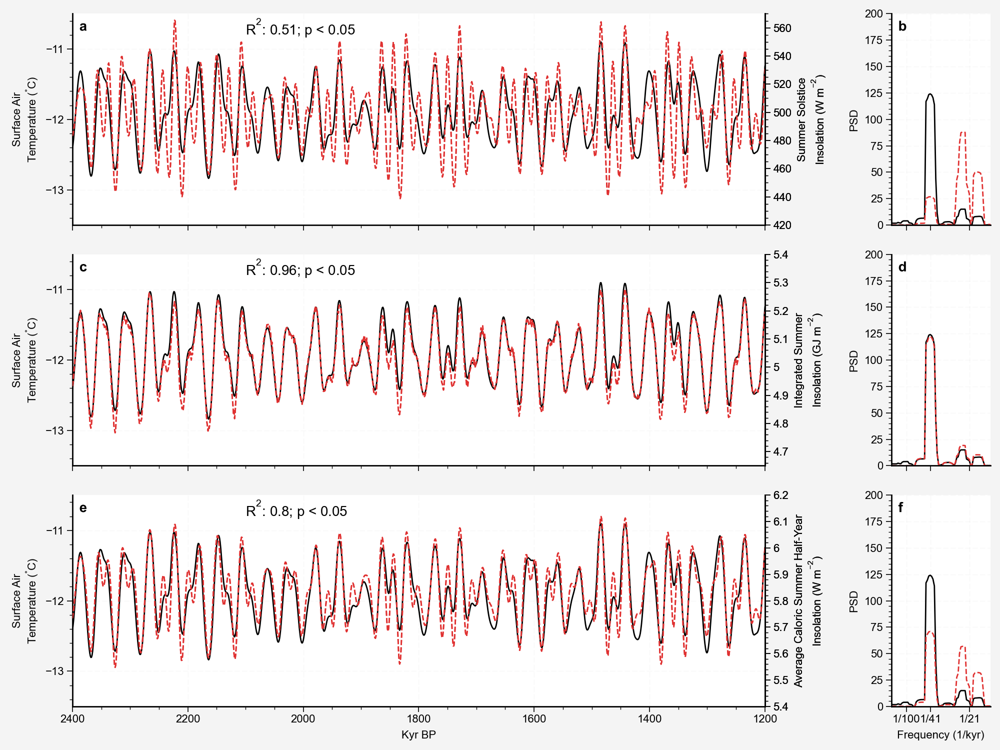

In [15]:
std = series['standard']
std_psd = spectral['standard']

# Calculate correlation of temperature with insolation metrics
# ============================================================

corr_ss  = std['Ta_60S_90S'].correlation(std['SSI_65S'])     # summer solstice
corr_isi = std['Ta_60S_90S'].correlation(std['ISI_65S'])     # integrated summer insolation
corr_clr = std['Ta_60S_90S'].correlation(std['CSH_65S'])     # caloric half-year

# R2
R2_ss  = np.round((corr_ss.r**2),2)
R2_isi = np.round((corr_isi.r**2),2)
R2_clr = np.round((corr_clr.r**2),2)

# Create figure
# =============

shape    = [[1,1,1,1,1,1,1,2,],[3,3,3,3,3,3,3,4,],[5,5,5,5,5,5,5,6,],]
fig, axs = pplt.subplots(shape, figsize = (10, 7.5), sharey=False, sharex=False, abc=True, abcbbox=False, abcloc='ul', abcsize=10)

# Plot surface air temperature
# ============================

# time series
for i in [0,2,4]:
    l1=axs[i].plot(std['Ta_60S_90S'].time, std['Ta_60S_90S'].value, lw =1, c='black')  # NH
    axs[i+1].plot(std_psd['Ta_60S_90S'].frequency, std_psd['Ta_60S_90S'].amplitude, lw =1, c='black') # spectral

# Plot summer solstice insolation
# =================================

# duplicate y-axis
axs0 = axs[0].twinx() 

# time series
axs0.plot(std['SSI_65S'].time, std['SSI_65S'].value, alpha = 1, ls = 'dashed', c='red8', lw = 1)                      # time-series
# spectral
axs[1].plot(std_psd['SSI_65S'].frequency, std_psd['SSI_65S'].amplitude, alpha = 1, ls = 'dashed', c='red8', lw = 1)  # spectral
axs0.format(ylim=(420, 570))
    
# Plot integrated summer insolation
# =================================

# duplicate y-axis
axs2 = axs[2].twinx() 

# time series
axs2.plot(std['ISI_65S'].time, std['ISI_65S'].value, alpha = 1, ls = 'dashed', c='red8', lw = 1)                    # time-series
axs[3].plot(std_psd['ISI_65S'].frequency, std_psd['ISI_65S'].amplitude, alpha = 1, ls = 'dashed', c='red8', lw = 1)  # spectral

# Plot caloric summer half year
# =============================

# duplicate y-axis
axs4 = axs[4].twinx() 
# time series
axs4.plot(std['CSH_65S'].time, std['CSH_65S'].value, alpha = 1, ls = 'dashed', c='red8', lw = 1)                      # time-series
# spectral
axs[5].plot(std_psd['CSH_65S'].frequency, std_psd['CSH_65S'].amplitude, alpha = 1, ls = 'dashed', c='red8', lw = 1)  # spectral
axs4.format(ylim=(5.4, 6.2))

# Print correlation
# ==================

axs[0].text(2100, -10.8, f'R$^{2}$: {R2_ss}; p < 0.05', fontsize=10)
axs[2].text(2100, -10.8, f'R$^{2}$: {R2_isi}; p < 0.05', fontsize=10)
axs[4].text(2100, -10.8, f'R$^{2}$: {R2_clr}; p < 0.05', fontsize=10)

# Formatting
# ==========

for i in [0,1,2,3,4,5]: 

    # spectral
    if i in [1,3,5]:
        # x-axis
        axs[i].format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xlim = (0.001, 0.06), xticklabelsize=10)
        axs[i].xaxis.set_ticklabels([])
        axs[i].format(ylim = (0, 200), ylabel='PSD')
        if i == 5:
            axs[i].format(xlabel = 'Frequency (1/kyr)', xticklabels=[r'1/100','1/41','1/21'])
            

    # time-series
    if i in [0,2,4]:
    
        axs[i].format(ylim=(-13.5, -10.5), ylocator=np.arange(-13, -9+1, 1))
        axs[i].format(ylabel='Surface Air\nTemperature ($^{\circ}$C)')

        if i in [0,2]:
            axs[i].xaxis.set_ticklabels([])
        else:
            axs[i].format(xlabel='Kyr BP')
        
# format twin axes
axs0.format(ylabel='Summer Solstice\nInsolation (W m$^{-2}$)')
axs2.format(ylabel='Integrated Summer\nInsolation (GJ m$^{-2}$)', ylim=(4.65,5.4))
axs4.format(ylabel='Average Caloric Summer Half-Year\nInsolation (W m$^{-2}$)')
for ax in [axs, axs0, axs2, axs4]:
    ax.format(ylabelsize=8, xlabelsize=8, titlesize=10, ticklabelsize=8)

# Save figure
# ===========

fig.save('paper2/fA6_temperature_vs_insolation_metrics_south.png', dpi=300)

## _Differences in polar temperature between the hemispheres_

In [17]:
# average polar air temperature (pat)
pat        = 0.5*(transient_experiment['standard']['Ta_60N_90N']+transient_experiment['standard']['Ta_60S_90S'])
pat_series = pyleo.Series(time =  time, value = pat, time_name = 'Kyr BP',  sort_ts='descending', verbose=False) # load into pyleoseries
pat_psd    = pat_series.standardize().interp().spectral(method='mtm', settings={'NW':4})

# calculate significance
pat_sig   = pat_psd.signif_test(qs=[0.99])
nhat_sig  = std_psd['Ta_60N_90N'].signif_test(qs=[0.99])
shat_sig  = std_psd['Ta_60N_90N'].signif_test(qs=[0.99])

Performing spectral analysis on individual series: 100%|█████████████████████████████| 200/200 [00:08<00:00, 22.93it/s]
Performing spectral analysis on individual series: 100%|█████████████████████████████| 200/200 [00:08<00:00, 22.55it/s]
Performing spectral analysis on individual series: 100%|█████████████████████████████| 200/200 [00:09<00:00, 21.22it/s]


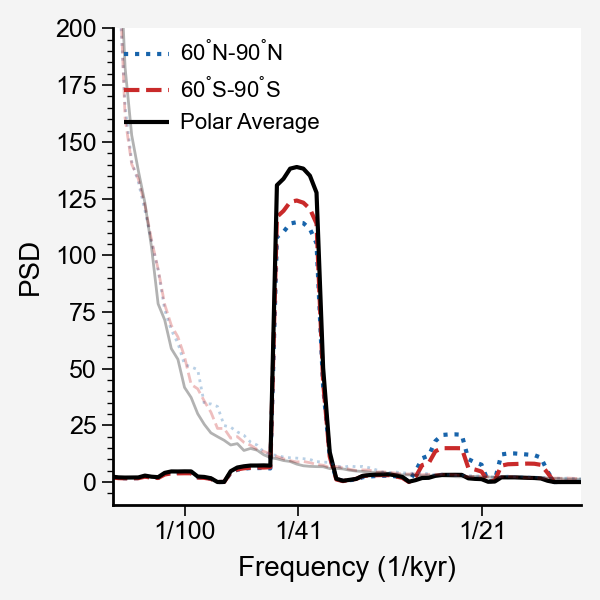

In [19]:
fig, axs = pplt.subplots(figsize = (3,3), sharex = False, sharey = True, grid = False)

# Plot power spectral density
l1=axs[0].plot(std_psd['Ta_60N_90N'].frequency, std_psd['Ta_60N_90N'].amplitude, c = 'blue9',  lw = 1.5, ls = 'dotted')
l2=axs[0].plot(std_psd['Ta_60S_90S'].frequency, std_psd['Ta_60S_90S'].amplitude, c = 'red9',  lw = 1.5, ls = 'dashed')
l3=axs[0].plot(pat_psd.frequency, pat_psd.amplitude, c = 'black', lw = 1.5, ls = 'solid')

axs[0].legend(handles=[l1,l2,l3], labels=['60$^{\circ}$N-90$^{\circ}$N', '60$^{\circ}$S-90$^{\circ}$S', 'Polar Average'], ncols=1, loc='ul',  prop = {"size": 8})


# Plot significance level
axs[0].plot(nhat_sig.signif_qs.psd_list[0].frequency, nhat_sig.signif_qs.psd_list[0].amplitude, c = 'blue9',  lw = 1, ls = 'dotted', alpha=0.3)
axs[0].plot(shat_sig.signif_qs.psd_list[0].frequency, shat_sig.signif_qs.psd_list[0].amplitude, c = 'red9',  lw = 1, ls = 'dashed', alpha=0.3)
axs[0].plot(pat_sig.signif_qs.psd_list[0].frequency, pat_sig.signif_qs.psd_list[0].amplitude, c = 'black', lw = 1, ls = 'solid', alpha=0.3)

axs.format(xlocator=[1/21, 1/41, 1/100], xminorlocator=[], xlim = (0.001, 0.06), xticklabelsize=10)
axs.format(ylim = (-10, 200))
axs.format(ylabel='PSD')
axs.format(xlabel='Frequency (1/kyr)')
axs.format(ticklabelsize=9, ticklabelweight="normal", labelsize=10, labelweight="normal", titlesize=10, xticklabels=[r'1/100','1/41','1/21'])
       
#axs[0].set_title('Northern Hemisphere (60$^{\circ}$ - 90$^{\circ}$N)', fontsize=10)
#axs[1].set_title('Southern Hemisphere (60$^{\circ}$ - 90$^{\circ}$S)', fontsize=10)
#axs[2].set_title('Polar Average (60$^{\circ}$ - 90$^{\circ}$N/S)', fontsize=10)

fig.save('paper2/f09_out_of_phase_cycles.png', dpi=300)

# ___Last Interglacial___

#### ___Load CMIP6 Ensemble Data___

Sea ice data freely available from Kageyama et al., 2021: "A multi-model CMIP6-PMIP4 study of Arctic sea ice at 127 ka: sea ice data compilation and model differences"

Zonal-mean temperature data provided by Anni Zhao and published in Otto-Bleisner et al., 2021: "Large-scale features of Last Interglacial climate: results from evaluating the lig127k simulations for the Coupled Model Intercomparison Project (CMIP6)–Paleoclimate Modeling Intercomparison Project (PMIP4)"

In [23]:
import pandas as pd

# Latitude
lig127k_lat = np.arange(-89.5,89.5+1,1)

# Sea-ice data
# ============

# Last Interglacial (LIG)
LIG_SIA        = pd.read_csv('LIG_SIA.txt',skipinitialspace=True,header=0, delimiter=';')
LIG_SIA_max    = pd.concat([pd.Series(['max']), LIG_SIA.iloc[:,1:].max(axis=0)])
LIG_SIA_min    = pd.concat([pd.Series(['min']), LIG_SIA.iloc[:,1:].min(axis=0)])
LIG_SIA.loc[len(LIG_SIA.index)] = LIG_SIA_max
LIG_SIA.iloc[17,0]='MAX'
LIG_SIA.loc[len(LIG_SIA.index)] = LIG_SIA_min
LIG_SIA.iloc[18,0]='MIN'

# Last Interglacial minus Pre-Industrial (LIG_PI)
LIG_PI_SIA     = pd.read_csv('LIG-PI_SIA.txt',skipinitialspace=True,header=0, delimiter=';')
LIG_PI_SIA_max = pd.concat([pd.Series(['max']), LIG_PI_SIA.iloc[:,1:].max(axis=0)])
LIG_PI_SIA_min = pd.concat([pd.Series(['min']), LIG_PI_SIA.iloc[:,1:].min(axis=0)])
LIG_PI_SIA.loc[len(LIG_PI_SIA.index)] = LIG_PI_SIA_max
LIG_PI_SIA.iloc[17,0]='MAX'
LIG_PI_SIA.loc[len(LIG_PI_SIA.index)] = LIG_PI_SIA_min
LIG_PI_SIA.iloc[18,0]='MIN'

# Zonal-Mean Temperature
# ======================

# Last Interglacial minus Pre-Industrial (LIG_PI)
LIG_PI_Ta   = pd.read_csv('PMIP4_lig127k_diff_zonal_1_tas_ann.csv',skipinitialspace=True,header=0)
maxValues   = LIG_PI_Ta.iloc[:,1:].max(axis=1)
minValues   = LIG_PI_Ta.iloc[:,1:].min(axis=1)
medValues   = LIG_PI_Ta.iloc[:,1:].median(axis=1)
avgValues   = LIG_PI_Ta.iloc[:,1:].mean(axis=1)
LIG_PI_Ta['max'] = maxValues
LIG_PI_Ta['min'] = minValues
LIG_PI_Ta['med'] = medValues

In [24]:
LIG_PI_Ta

,Unnamed: 0,ACCESS-ESM1-5,AWI-ESM-1-1-LR,AWI-ESM-2-1-LR,CESM2,CNRM-CM6-1,EC-Earth3-LR,FGOALS-f3-L,FGOALS-g3,GISS-E2-1-G,...,IPSL-CM6A-LR,MIROC-ES2L,MPI-ESM1-2-LR,NESM3,NorESM1-F,NorESM2-LM,average,max,min,med
0,0,0.869361,0.499530,-0.299059,0.149640,0.883400,-0.206352,-0.107482,0.676195,-0.512623,...,0.229704,0.342419,0.382023,1.040092,-0.543107,0.279575,0.261876,1.040092,-0.543107,0.282195
1,1,0.872940,0.498244,-0.296690,0.139038,0.887250,-0.185111,-0.136149,0.711430,-0.488643,...,0.190811,0.342419,0.379716,1.041038,-0.517584,0.294159,0.264283,1.041038,-0.517584,0.279221
2,2,0.928521,0.480427,-0.263914,0.133593,0.894272,-0.157939,-0.199515,0.746642,-0.440705,...,0.156769,0.324973,0.347791,1.054160,-0.446064,0.313251,0.269310,1.054160,-0.446064,0.291281
3,3,0.989522,0.472433,-0.217516,0.135003,0.852431,-0.134456,-0.246313,0.781851,-0.398531,...,0.107941,0.277088,0.330059,1.066116,-0.344597,0.335277,0.275697,1.066116,-0.398531,0.276393
4,4,1.013593,0.498696,-0.123625,0.148637,0.833321,-0.111876,-0.271150,0.817080,-0.362123,...,0.059059,0.229204,0.361828,1.074007,-0.301269,0.356172,0.286799,1.074007,-0.362123,0.258002
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,175,2.495213,-0.408747,0.464426,1.301854,1.771843,3.663073,0.499596,4.528559,1.529294,...,1.343508,0.229772,0.414188,1.014221,0.925941,0.940752,1.622409,6.478124,-0.408747,1.158038
176,176,2.524928,-0.416873,0.449170,1.281870,1.779374,3.570842,0.522680,4.743654,1.525324,...,1.308126,0.236436,0.389353,1.072841,0.924373,0.963897,1.632302,6.502286,-0.416873,1.177355
177,177,2.548916,-0.426851,0.426860,1.263208,1.781519,3.473385,0.541755,4.958629,1.540049,...,1.298757,0.243099,0.373060,1.141787,0.911358,0.980660,1.643850,6.505851,-0.426851,1.202497
178,178,2.546292,-0.437358,0.402530,1.248910,1.763431,3.388228,0.568348,5.173616,1.573498,...,1.278336,0.245527,0.359217,1.213688,0.903725,0.994157,1.656242,6.502024,-0.437358,1.231299


#### ___Load ZEMBA LIG and PI simulation___

In [37]:
version = 'moist'
res = 5.0
# Last Interglacial
with open( f"output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    lig_data = pickle.load(file)['ligStateYear']

with open( f"output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    Var = pickle.load(file)['Var'] 
    

# Pre-Industrial
with open( f"output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    pi_data = pickle.load(file)['piStateYear']  

# constants
with open( f"output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    var = pickle.load(file)['Var'] 

# LIG insolation
with open( f"output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    lig_inso = pickle.load(file)['ligI']['ligI'] 

# PI insolation
with open( f"output_orb_lig_{version}_res{res}.pkl", 'rb') as file:
    pi_inso = pickle.load(file)['piI']['ligI'] 


#### ___Plot comparision___

In [38]:
# Function to calculate monthly averages
def calculate_monthlies(x, lat):
    '''
    Returns monthly values for StateYear variable.
    '''
    # initialize monthly array
    monthly_array = np.zeros((lat, 12))
    # days in months
    days_in_month = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
    # months
    monthly_array[:,0]  = x[:, 0:31].mean(axis=1)       # jan
    monthly_array[:,1]  = x[:, 31:59].mean(axis=1)      # feb
    monthly_array[:,2]  = x[:, 59:90].mean(axis=1)      # mar
    monthly_array[:,3]  = x[:, 90:120].mean(axis=1)     # apr
    monthly_array[:,4]  = x[:, 120:151].mean(axis=1)    # may
    monthly_array[:,5]  = x[:, 151:181].mean(axis=1)    # jun
    monthly_array[:,6]  = x[:, 181:212].mean(axis=1)    # jul
    monthly_array[:,7]  = x[:, 212:243].mean(axis=1)    # aug
    monthly_array[:,8]  = x[:, 243:273].mean(axis=1)    # sep
    monthly_array[:,9]  = x[:, 273:304].mean(axis=1)    # oct
    monthly_array[:,10] = x[:, 304:334].mean(axis=1)    # nov
    monthly_array[:,11] = x[:, 334:365].mean(axis=1)    # dec
    return monthly_array

zemba_lig_sic_nh    = calculate_monthlies(lig_data['si_area_nh'], Var['lat'].size)
zemba_lig_pi_sic_nh = calculate_monthlies(lig_data['si_area_nh']-pi_data['si_area_nh'], Var['lat'].size)

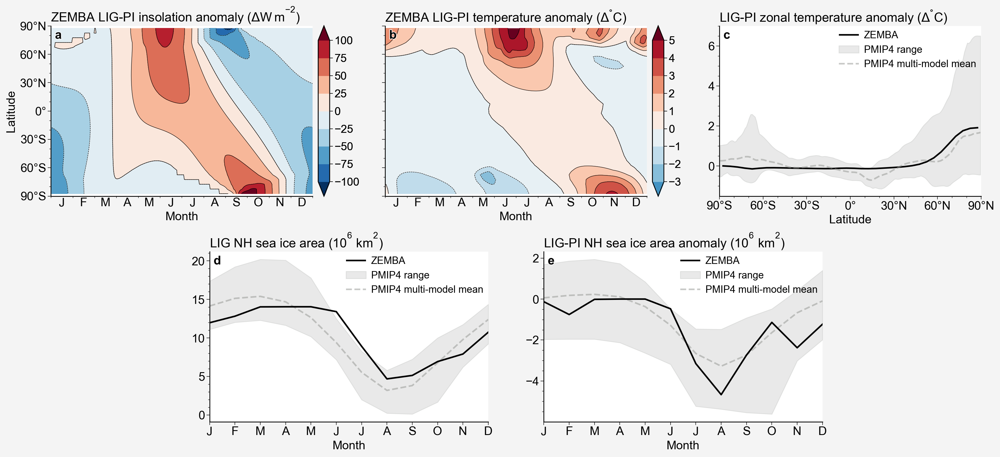

In [39]:
# Plot comparision of insolation, temperature and sea ice
# =======================================================

# define figure
shape = [[1,1,2,2,3,3],
         [0,4,4,5,5,0],]
fig, axs = pplt.subplots(shape, figsize=(17.5,8), sharex=False, sharey=False, space=5, abc=True, abcloc='ul', grid=False)

# insolation anomaly
days, lats = np.meshgrid(np.arange(1, 366, 1), var["lat"])
c=axs[0].contourf(days, lats, lig_inso - pi_inso, extend = 'both', levels = np.arange(-100,100+25,25))
axs[0].contour(days, lats, lig_inso - pi_inso, levels = np.arange(0,100+25,25), ls = 'solid', color = 'black', lw = 0.5)
axs[0].contour(days, lats, lig_inso - pi_inso, levels = np.arange(-100,0+25,25), ls = 'dashed', color = 'black', lw = 0.5)

cb=axs[0].colorbar(c, loc='r')
cb.ax.tick_params(labelsize=14) 

# temperature anomaly
c=axs[1].contourf(days, lats, lig_data["Ta"]-pi_data["Ta"], extend = 'both', levels = np.arange(-3,5+1,1))
axs[1].contour(days, lats, lig_data["Ta"]-pi_data["Ta"], levels = np.arange(0,5+1,1), ls = 'solid', color = 'black', lw = 0.5)
axs[1].contour(days, lats, lig_data["Ta"]-pi_data["Ta"], levels = np.arange(-3,0+1,1), ls = 'dashed', color = 'black', lw = 0.5)

cb=axs[1].colorbar(c, loc='r')
cb.ax.tick_params(labelsize=14) 

# zonal mean LIG-PI versus CMIP6 Ensemble
l1=axs[2].plot(var['lat'], lig_data['Ta'].mean(axis=1)-pi_data['Ta'].mean(axis=1), color = 'black', lw = 2)
axs[2].format(ylim=(-1.5, 7), xlabel = 'Latitude')
l2=axs[2].plot(lig127k_lat, LIG_PI_Ta['average'],color='grey',alpha=0.5,lw=2,linestyle='dashed',label='MMM')
#axs[2].plot(lat,data['med'],color='grey',alpha=0.5,lw=2,linestyle='dashed',label='MMM')
l3=axs[2].fill_between(lig127k_lat, LIG_PI_Ta['max'], LIG_PI_Ta['min'],color='grey',alpha=0.2)
axs[2].legend(handles=[l1, l3, l2], labels = ['ZEMBA', 'PMIP4 range',  'PMIP4 multi-model mean'], ncols=1, loc='ur')
axs[2].yaxis.label.set_visible(False)

# Last Interglacial Sea Ice
axs[3].plot(np.arange(1, 12+1), LIG_SIA.iloc[16,1:13],color='grey',alpha=0.5,lw=2,linestyle='dashed')
g=np.array(LIG_SIA.iloc[17,1:13].to_numpy(), dtype=float)
g1=np.array(LIG_SIA.iloc[18,1:13].to_numpy(), dtype=float)
axs[3].fill_between(np.arange(1, 12+1), g, g1,color='grey',alpha=0.2)
axs[3].plot(np.arange(1, 12+1), zemba_lig_sic_nh[0,:]*1e-12,color='black',alpha=1,lw=2,linestyle='solid')
axs[3].legend(handles=[l1, l3, l2], labels = ['ZEMBA', 'PMIP4 range',  'PMIP4 multi-model mean'], ncols=1, loc='ur')
axs[3].yaxis.label.set_visible(False)

# Last Interglacial minus Pre-Industrial Sea Ice
axs[4].plot(np.arange(1, 12+1), LIG_PI_SIA.iloc[16,1:13],color='grey',alpha=0.5,lw=2,linestyle='dashed')
g=np.array(LIG_PI_SIA.iloc[17,1:13].to_numpy(), dtype=float)
g1=np.array(LIG_PI_SIA.iloc[18,1:13].to_numpy(), dtype=float)
axs[4].fill_between(np.arange(1, 12+1), g, g1,color='grey',alpha=0.2)
axs[4].plot(np.arange(1, 12+1), zemba_lig_pi_sic_nh[0,:]*1e-12,color='black',alpha=1,lw=2,linestyle='solid')
axs[4].legend(handles=[l1, l3, l2], labels = ['ZEMBA', 'PMIP4 range',  'PMIP4 multi-model mean'], ncols=1, loc='ur')
axs[4].yaxis.label.set_visible(False)

# formatting
# ==========

# contour plots
for i in [0,1]:
    axs[i].format(
        # x-axis
        xlabel = 'Month', xlim=(0, 365), xlocator=np.linspace(30, 365, 12) - 15,
        xminorlocator=np.linspace(0, 365, 13), xticklabels=["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"],
        # y-axis
        ylim=(-90, 90), ylocator=[-90, -60, -30, 0, 30, 60, 90] ,yformatter='deglat',
        yminorlocator=[-90, -80, -70, -60, -50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90],)
    axs[i].tick_params(axis='x', length=0)
    if i == 0:
        axs[i].format(ylabel='Latitude')
    if i == 1:
        axs[i].yaxis.set_ticklabels([])
    


# zonal temperature plots
for i in [2]:
    axs[i].format(
        # x-axis
        xlabel = 'Latitude', xlim=(-90, 90), xlocator=[-90, -60, -30, 0, 30, 60, 90] ,xformatter='deglat',
        xminorlocator=[-90, -80, -70, -60, -50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90],)

# sea ice plots
for i in [3,4]:
    axs[i].format(
        # x-axis
        xlabel = 'Month', xlim=(1, 12), xlocator=np.linspace(1, 12, 12),
        xminorlocator=[], xticklabels=["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"],) 

# titles

axs[0].set_title('ZEMBA LIG-PI insolation anomaly ($\Delta W \: m^{-2}$)', loc = 'left')
axs[1].set_title('ZEMBA LIG-PI temperature anomaly ($\Delta ^{\circ}C$)', loc = 'left')
axs[2].set_title('LIG-PI zonal temperature anomaly ($\Delta ^{\circ}C$)', loc = 'left')
axs[3].set_title('LIG NH sea ice area (10$^{6}$ km$^{2}$)', loc = 'left')
axs[4].set_title('LIG-PI NH sea ice area anomaly (10$^{6}$ km$^{2}$)', loc = 'left')
axs.format(titlesize=16, labelsize=15, ticklabelsize=15)

fig.save('paper2/f02_LIG.png', dpi=300)
#fig.save('LIG2.png', transparent=True, dpi=300)


In [29]:
# PRINT CHANGE IN GLOBAL MEAN TEMPERATURE
# =======================================

print('Change in GMAT: ' + str( np.round( np.average( lig_data['Ta'].mean(axis=1)-pi_data['Ta'].mean(axis=1), weights=Var['sarea']), 2) ) )
print('Change in Ocean GMAT: ' + str( np.round( np.average( lig_data['Tos'].mean(axis=1)[idxo['GLB']]-pi_data['Tos'].mean(axis=1)[idxo['GLB']], weights=Var['oarea'][idxo['GLB']]), 2) ) )
print('Change in Land GMAT: ' + str( np.round( np.average( lig_data['Tl'].mean(axis=1)[idxl['GLB']]-pi_data['Tl'].mean(axis=1)[idxl['GLB']], weights=Var['larea'][idxl['GLB']]), 2) ) )

print('Change in 60-90N: ' + str( np.round( np.average( lig_data['Ta'].mean(axis=1)[idx['60N_90N']]-pi_data['Ta'].mean(axis=1)[idx['60N_90N']], weights=Var['sarea'][idx['60N_90N']]), 2) ) )
print('Change in 60-90S: ' + str( np.round( np.average( lig_data['Ta'].mean(axis=1)[idx['60S_90S']]-pi_data['Ta'].mean(axis=1)[idx['60S_90S']], weights=Var['sarea'][idx['60S_90S']]), 2) ) )


Change in GMAT: 0.02
Change in Ocean GMAT: 0.02
Change in Land GMAT: 0.07
Change in 60-90N: 1.24
Change in 60-90S: -0.1


# _Variability in the orbital experiments_

Shows variability in temperature, sea ice and snow cover amongst the orbital experiments.

### _Tabulated data of variability (average, standard deviation, range)_

In [31]:
# Create tables
# ============

df            = {} # dictionary for dataframes
df['Ta']      = pd.DataFrame(columns=['90-60S', '60-30S', '30S-30N', '30-60N', '60-90N', 'SH', 'NH', 'Global'])
df['si_area'] = pd.DataFrame(columns=['90-60S', '60-30S', '30S-30N', '30-60N', '60-90N', 'SH', 'NH', 'Global'])
df['sc_area'] = pd.DataFrame(columns=['90-60S', '60-30S', '30S-30N', '30-60N', '60-90N', 'SH', 'NH', 'Global'])
df['precip']  = pd.DataFrame(columns=['90-60S', '60-30S', '30S-30N', '30-60N', '60-90N', 'SH', 'NH', 'Global'])

# Fill tables
# ===========

names_of_experiments = ['Standard', 'Obliquity', 'Precession', 'Fix Sea Ice', 'Fix Snow Cover', 'Fix sea ice and snow cover']

i=0
for exp in [series['standard'], series['obliquity'], series['precession'], series['fxoa'], series['fxla'], series['fxoa_fxla']]: #------------------------------------------ for experiment

    for var in ['Ta', 'si_area', 'sc_area', 'precip']: #-------------------------------------- for variable
        
        list = []
    
        for index in ['60S_90S', '30S_60S', 'TRP', '30N_60N', '60N_90N', 'SH', 'NH', 'GLB']: #-- for region

            # calculate average, standard deviation and range
            average            = exp[f"{var}_{index}"].value.mean().round(2)
            standard_deviation = exp[f"{var}_{index}"].value.std().round(2)
            range              = (exp[f"{var}_{index}"].value.max()-exp[f"{var}_{index}"].value.min()).round(2)
        
            list.append(f"{average}±{standard_deviation} [{range}]")
            
        df[var].loc[names_of_experiments[i]] = list

    i=i+1

In [32]:
df['Ta']

,90-60S,60-30S,30S-30N,30-60N,60-90N,SH,NH,Global
Standard,-11.9±0.44 [1.94],12.76±0.06 [0.26],24.49±0.09 [0.4],12.92±0.11 [0.56],-10.75±0.72 [3.3],15.31±0.06 [0.27],15.54±0.12 [0.62],15.43±0.08 [0.4]
Obliquity,-11.86±0.41 [1.63],12.73±0.02 [0.08],24.44±0.08 [0.33],12.84±0.07 [0.28],-11.07±0.63 [2.5],15.28±0.02 [0.07],15.45±0.07 [0.28],15.36±0.05 [0.18]
Precession,-11.83±0.19 [0.83],12.76±0.06 [0.24],24.47±0.05 [0.18],12.93±0.08 [0.36],-10.64±0.34 [1.62],15.31±0.06 [0.26],15.55±0.09 [0.41],15.43±0.06 [0.27]
Fix Sea Ice,-11.75±0.16 [0.74],12.76±0.05 [0.27],24.48±0.1 [0.46],12.9±0.07 [0.32],-10.83±0.14 [0.6],15.33±0.06 [0.29],15.52±0.06 [0.32],15.42±0.06 [0.3]
Fix Snow Cover,-11.85±0.41 [1.8],12.78±0.05 [0.25],24.52±0.1 [0.45],13.08±0.07 [0.34],-10.3±0.44 [2.01],15.34±0.06 [0.26],15.68±0.07 [0.33],15.51±0.06 [0.28]
Fix sea ice and snow cover,-11.72±0.15 [0.68],12.79±0.05 [0.27],24.52±0.1 [0.49],13.04±0.07 [0.37],-10.62±0.14 [0.72],15.36±0.06 [0.3],15.62±0.07 [0.39],15.49±0.06 [0.34]


In [33]:
df['si_area']

,90-60S,60-30S,30S-30N,30-60N,60-90N,SH,NH,Global
Standard,8.87±0.54 [2.27],0.0±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],11.59±0.63 [3.07],8.87±0.54 [2.27],11.59±0.63 [3.07],20.45±0.86 [3.59]
Obliquity,8.68±0.45 [1.68],0.0±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],11.93±0.47 [1.74],8.68±0.45 [1.68],11.93±0.47 [1.74],20.61±0.92 [3.41]
Precession,8.83±0.41 [1.81],0.0±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],11.5±0.42 [2.1],8.83±0.41 [1.81],11.5±0.42 [2.1],20.34±0.18 [0.86]
Fix Sea Ice,8.61±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],11.78±0.0 [0.0],8.61±0.0 [0.0],11.78±0.0 [0.0],20.39±0.0 [0.0]
Fix Snow Cover,8.84±0.52 [2.21],0.0±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],11.34±0.38 [1.85],8.84±0.52 [2.21],11.34±0.38 [1.85],20.18±0.7 [2.98]
Fix sea ice and snow cover,8.61±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],11.78±0.0 [0.0],8.61±0.0 [0.0],11.78±0.0 [0.0],20.39±0.0 [0.0]


In [34]:
df['sc_area']

,90-60S,60-30S,30S-30N,30-60N,60-90N,SH,NH,Global
Standard,14.08±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],4.53±0.24 [1.18],12.7±0.36 [1.94],14.08±0.0 [0.0],17.22±0.37 [1.75],31.3±0.37 [1.75]
Obliquity,14.08±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],4.48±0.05 [0.19],12.87±0.22 [0.89],14.08±0.0 [0.0],17.35±0.27 [1.09],31.42±0.27 [1.09]
Precession,14.08±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],4.53±0.24 [1.1],12.67±0.25 [1.26],14.08±0.0 [0.0],17.19±0.21 [0.96],31.27±0.21 [0.96]
Fix Sea Ice,14.08±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],4.54±0.33 [1.54],12.75±0.13 [0.82],14.08±0.0 [0.0],17.29±0.28 [1.31],31.37±0.28 [1.31]
Fix Snow Cover,14.08±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],4.43±0.0 [0.0],12.8±0.0 [0.0],14.08±0.0 [0.0],17.23±0.0 [0.0],31.31±0.0 [0.0]
Fix sea ice and snow cover,14.08±0.0 [0.0],0.0±0.0 [0.0],0.0±0.0 [0.0],4.43±0.0 [0.0],12.8±0.0 [0.0],14.08±0.0 [0.0],17.23±0.0 [0.0],31.31±0.0 [0.0]
